# Projeto de Sinais e Sistemas: vibração de drones com hélices saudáveis e defeituosas

> Grupo 11: Carolina Santiago de Medeiros, Karolyne Bezerra Rocha, Milla Rwana de Araújo Silva.

Links importantes:
- [Proposta da atividade](../especifica%C3%A7%C3%B5es/Projeto%20Sinais%20e%20Sistemas%202026.2.pdf)
- [Slides de proposta do projeto](../especifica%C3%A7%C3%B5es/Projeto%20de%20Sinais%20e%20Sistemas%202026.2.pdf)
- [Dataset DronePropB](https://data.mendeley.com/datasets/xkvfjmm8zg/1)
- [Relatório parcial (PDF)](../relatorio.pdf)

## 0. Configuração

Usamos só `numpy`, `pandas`, `matplotlib` e `scipy` (instalação e versões no `README.md`). Para rodar, baixe o DronePropB no Mendeley Data (*Download All*), descompacte e coloque a pasta `DronePropB Ground Testing Dataset`, a que contém os arquivos `.mat`, ao lado deste notebook (o passo a passo está no `README.md`).

Ao executar todas as células, o notebook gera a tabela de características `caracteristicas_janelas.csv`, ao lado dele, e salva as figuras do relatório em `output/figuras/` e as tabelas auxiliares em `output/tabelas/`.

In [1]:
import os, glob, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import scipy.io
from scipy.signal import decimate

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
pd.set_option('display.float_format', lambda v: f'{v:.4g}')

CORES = {'saudável': '#2b7bba', 'defeito': '#d95f02'}
VELOCIDADES = ['SP1', 'SP2', 'SP3']

In [2]:
# Pasta com os arquivos .mat do DronePropB, ao lado deste notebook (ver README.md)
PASTA = 'DronePropB Ground Testing Dataset'

# Saídas: a tabela de características fica ao lado do notebook; figuras e tabelas auxiliares, em output/
PASTA_FIGURAS = os.path.join('output', 'figuras')
PASTA_TABELAS = os.path.join('output', 'tabelas')
os.makedirs(PASTA_FIGURAS, exist_ok=True)
os.makedirs(PASTA_TABELAS, exist_ok=True)

arquivos = sorted(glob.glob(os.path.join(PASTA, '*.mat')))
assert arquivos, f'Nenhum arquivo .mat encontrado em "{PASTA}". Veja o README.md para obter o dataset.'
print(len(arquivos), 'arquivos .mat encontrados em', PASTA)

111 arquivos .mat encontrados em DronePropB Ground Testing Dataset


## 3.1 Seleção, caracterização e preparação dos dados

### 3.1.1 Arquivos e metadados

Os nomes seguem o padrão `F{falha}_SV{severidade}_SP{velocidade}_C{configuração}[_R{repetição}].mat`:

| campo | valores | significado |
|---|---|---|
| `F` | 0, 1, 2, 3 | condição da hélice: F0 é a saudável, e F1, F2 e F3 são três tipos de defeito |
| `SV` | 0, 1, 2, 3 | severidade do defeito (0 para a saudável, de 1 a 3 em ordem crescente) |
| `SP` | 0, 1, 2, 3 | velocidade de operação (SP1 < SP2 < SP3; SP0 só aparece em C4) |
| `C` | 1, 2, 3, 4 | configuração (provavelmente um experimento diferente) |
| `R` | 1, 2, 3 | repetição (só os ensaios saudáveis têm três) |

O significado de `C` não está documentado nos arquivos; o mais provável é que cada configuração seja um experimento diferente (por exemplo, com outro drone ou outro modelo de hélice), por isso nunca misturamos configurações numa comparação.

In [3]:
def ler_nome(caminho):
    """Converte 'F1_SV3_SP2_C1.mat' em {'F': 1, 'SV': 3, 'SP': 2, 'C': 1, 'R': 1}."""
    nome = os.path.basename(caminho).replace('.mat', '')
    campos = {k: int(v) for k, v in re.findall(r'([A-Z]+)(\d+)', nome)}
    campos.setdefault('R', 1)  # registros com defeito têm uma única repetição
    campos['id'] = nome
    return campos

inventario = pd.DataFrame([ler_nome(a) for a in arquivos])
inventario['condição'] = np.where(inventario['F'] == 0, 'saudável (F0)', 'defeito (F1 a F3)')
pd.crosstab([inventario['C'], inventario['condição']], inventario['SP'].map(lambda s: f'SP{s}'))

SP                   SP0  SP1  SP2  SP3
C condição                             
1 defeito (F1 a F3)    0    9    9    9
  saudável (F0)        0    3    3    3
2 defeito (F1 a F3)    0    9    9    9
  saudável (F0)        0    3    3    3
3 defeito (F1 a F3)    0    9    9    9
  saudável (F0)        0    3    3    3
4 saudável (F0)        3    0    0    0

In [4]:
# Estrutura interna de um arquivo
exemplo = scipy.io.loadmat(os.path.join(PASTA, 'F0_SV0_SP1_C1_R1.mat'))
for chave in ['AccData', 'IMUData']:
    s = exemplo[chave][0, 0]
    print(chave, '| campos:', s.dtype.names, '| fs =', int(s['samplingRate'][0, 0]), 'Hz | Vib_Data:', s['Vib_Data'].shape)

AccData | campos: ('DATE', 'samplingRate', 't', 'Vib_Data') | fs = 10000 Hz | Vib_Data: (1, 600000)
IMUData | campos: ('t', 'Vib_Data', 'samplingRate') | fs = 1000 Hz | Vib_Data: (3, 82344)


Cada arquivo traz três estruturas:

- `AccData`: acelerômetro piezoelétrico, um eixo, $f_s = 10$ kHz, unidade não registrada (usamos u.a., unidade arbitrária);
- `IMUData`: IMU de três eixos, 1 kHz, em m/s², com duração diferente e sem sincronia com o piezo;
- `BatteryVolt`: tensão da bateria.

Usamos o piezo porque, pelo critério de Nyquist (Lecture 13, slide 23; fundamentado em 3.3.7), uma taxa $f_s$ só representa frequências abaixo de $f_s/2$. Com 10 kHz, o piezo cobre a rotação e vários harmônicos (até cerca de 800 Hz) e ainda deixa margem para o estudo de aliasing, enquanto a IMU, com 1 kHz, já perderia o quarto harmônico de SP3 (cerca de 530 Hz, acima de 500 Hz).

### 3.1.2 Registros escolhidos

Configuração C1 completa nas três velocidades: 9 registros saudáveis (F0, repetições R1 a R3) e 27 com defeito (F1 a F3, severidades SV1 a SV3), todos com o piezo, no mesmo eixo, com $f_s = 10$ kHz e 60 s (600.000 amostras).

In [5]:
def carregar_piezo(caminho):
    """Lê o sinal do acelerômetro piezo (AccData): sinal, tempo, fs e data."""
    acc = scipy.io.loadmat(caminho)['AccData'][0, 0]
    x = acc['Vib_Data'].ravel().astype(float)
    t = acc['t'].ravel()
    fs = int(acc['samplingRate'][0, 0])
    return x, t, fs, str(acc['DATE'][0])

# Seleção: configuração C1, velocidades SP1 a SP3, todos os saudáveis (R1 a R3) e todos os defeituosos
selecao = inventario[(inventario['C'] == 1) & (inventario['SP'] > 0)].sort_values(['SP', 'F', 'SV', 'R'])

sinais, linhas = {}, []
for _, r in selecao.iterrows():
    x, t, fs, data = carregar_piezo(os.path.join(PASTA, r['id'] + '.mat'))
    sinais[r['id']] = x
    linhas.append({'id': r['id'],
                   'classe': 'saudável' if r['F'] == 0 else 'defeito',
                   'falha (F)': r['F'], 'severidade (SV)': r['SV'], 'velocidade': f"SP{r['SP']}",
                   'repetição (R)': r['R'], 'data': data, 'sensor': 'piezo (AccData)',
                   'eixo': '1 eixo', 'unidade': 'u.a.', 'fs (Hz)': fs,
                   'N amostras': len(x), 'duração (s)': len(x) / fs})

registros = pd.DataFrame(linhas)
FS = registros['fs (Hz)'].iloc[0]
registros

,id,classe,falha (F),severidade (SV),velocidade,repetição (R),data,sensor,eixo,unidade,fs (Hz),N amostras,duração (s)
0,F0_SV0_SP1_C1_R1,saudável,0,0,SP1,1,25-Sep-2024,piezo (AccData),1 eixo,u.a.,10000,600000,60
1,F0_SV0_SP1_C1_R2,saudável,0,0,SP1,2,11-Nov-2024,piezo (AccData),1 eixo,u.a.,10000,600000,60
2,F0_SV0_SP1_C1_R3,saudável,0,0,SP1,3,11-Nov-2024,piezo (AccData),1 eixo,u.a.,10000,600000,60
3,F1_SV1_SP1_C1,defeito,1,1,SP1,1,25-Sep-2024,piezo (AccData),1 eixo,u.a.,10000,600000,60
4,F1_SV2_SP1_C1,defeito,1,2,SP1,1,25-Sep-2024,piezo (AccData),1 eixo,u.a.,10000,600000,60
5,F1_SV3_SP1_C1,defeito,1,3,SP1,1,25-Sep-2024,piezo (AccData),1 eixo,u.a.,10000,600000,60
6,F2_SV1_SP1_C1,defeito,2,1,SP1,1,25-Sep-2024,piezo (AccData),1 eixo,u.a.,10000,600000,60
7,F2_SV2_SP1_C1,defeito,2,2,SP1,1,25-Sep-2024,piezo (AccData),1 eixo,u.a.,10000,600000,60
8,F2_SV3_SP1_C1,defeito,2,3,SP1,1,25-Sep-2024,piezo (AccData),1 eixo,u.a.,10000,600000,60
9,F3_SV1_SP1_C1,defeito,3,1,SP1,1,25-Sep-2024,piezo (AccData),1 eixo,u.a.,10000,600000,60


In [6]:
registros.groupby(['velocidade', 'classe']).size().unstack()

classe,defeito,saudável
velocidade,,
SP1,9,3
SP2,9,3
SP3,9,3


Por que essas comparações são válidas:

- saudável e defeito são comparados sempre na mesma velocidade, com o mesmo sensor, eixo e taxa, porque a velocidade muda muito a vibração (3.2 e 3.6);
- C1 é a configuração principal. Os saudáveis de C2 são cópias idênticas dos de C1, mas os defeituosos são diferentes (3.1.3); como os dados não dizem a qual experimento esses saudáveis pertencem, registramos isso como limitação e usamos C2 só como checagem em 3.6;
- C3 tem registros curtos (cerca de 20 s) e de outra data, e C4 só tem saudáveis em SP0;
- ressalva: o saudável R1 é do mesmo dia dos defeituosos (25/09/2024), mas R2 e R3 são de 11/11/2024, então nos exemplos visuais usamos sempre o R1.

### 3.1.3 Verificação dos dados

In [7]:
verificacao = []
for _, r in selecao.iterrows():
    x, t, fs, _ = carregar_piezo(os.path.join(PASTA, r['id'] + '.mat'))
    dt = np.diff(t)
    verificacao.append({'id': r['id'],
                        'NaN/inf': int((~np.isfinite(x)).sum()),
                        'passo de tempo constante': bool(np.allclose(dt, 1 / fs)),
                        'média': x.mean(), 'desvio padrão': x.std(),
                        '|média| / desvio': abs(x.mean()) / x.std(),
                        'passo de quantização': np.diff(np.unique(x)).min(),
                        'níveis distintos': len(np.unique(x))})
verificacao = pd.DataFrame(verificacao)
print('Registros com NaN/inf:', (verificacao['NaN/inf'] > 0).sum())
print('Registros com passo de tempo irregular:', (~verificacao['passo de tempo constante']).sum())
print('Maior |média|/desvio padrão:', round(verificacao['|média| / desvio'].max(), 3))
print('Passo de quantização:', f"{verificacao['passo de quantização'].min():.2e} u.a.",
      '| níveis distintos por registro:', verificacao['níveis distintos'].min(), 'a', verificacao['níveis distintos'].max())

Registros com NaN/inf: 0
Registros com passo de tempo irregular: 0
Maior |média|/desvio padrão: 0.053
Passo de quantização: 3.20e-04 u.a. | níveis distintos por registro: 692 a 9865


In [8]:
# Os saudáveis de C1 e C2 são o mesmo sinal? E os registros com defeito?
iguais = []
for sp in VELOCIDADES:
    for rep in [1, 2, 3]:
        a, _, _, _ = carregar_piezo(os.path.join(PASTA, f'F0_SV0_{sp}_C1_R{rep}.mat'))
        b, _, _, _ = carregar_piezo(os.path.join(PASTA, f'F0_SV0_{sp}_C2_R{rep}.mat'))
        iguais.append(np.array_equal(a, b))
print(f'{sum(iguais)} de {len(iguais)} pares F0 C1/C2 têm exatamente o mesmo sinal')

iguais_def, datas_def = [], set()
for _, r in inventario[(inventario['C'] == 1) & (inventario['F'] > 0)].iterrows():
    a, _, _, data_a = carregar_piezo(os.path.join(PASTA, r['id'] + '.mat'))
    b, _, _, data_b = carregar_piezo(os.path.join(PASTA, r['id'].replace('_C1', '_C2') + '.mat'))
    iguais_def.append(np.array_equal(a, b))
    datas_def.update([data_a, data_b])
print(f'{sum(iguais_def)} de {len(iguais_def)} pares com defeito C1/C2 têm o mesmo sinal | datas de gravação: {sorted(datas_def)}')

9 de 9 pares F0 C1/C2 têm exatamente o mesmo sinal


0 de 27 pares com defeito C1/C2 têm o mesmo sinal | datas de gravação: ['25-Sep-2024']


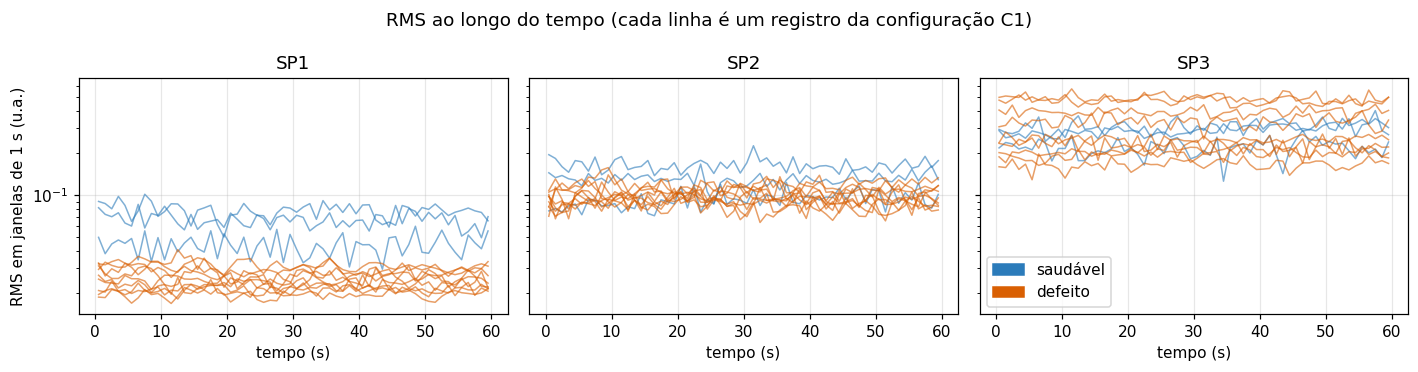

In [9]:
# Estacionariedade: RMS de cada segundo ao longo dos 60 s de cada registro
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, sp in zip(axes, VELOCIDADES):
    for _, r in registros[registros['velocidade'] == sp].iterrows():
        x = sinais[r['id']]
        rms_seg = np.sqrt(np.mean(x[: len(x) // FS * FS].reshape(-1, FS) ** 2, axis=1))
        ax.plot(np.arange(len(rms_seg)) + 0.5, rms_seg, color=CORES[r['classe']], alpha=0.6, lw=1)
    ax.set_title(f'{sp}')
    ax.set_xlabel('tempo (s)')
axes[0].set_ylabel('RMS em janelas de 1 s (u.a.)')
axes[0].set_yscale('log')
axes[-1].legend(handles=[Patch(color=c, label=k) for k, c in CORES.items()])
fig.suptitle('RMS ao longo do tempo (cada linha é um registro da configuração C1)')
plt.tight_layout(); plt.show()

Resultado da verificação:

- nenhum valor ausente ou infinito, e passo de tempo constante ($1/f_s$) nos 36 registros;
- média de no máximo 5,3 % do desvio padrão, ou seja, apenas um pequeno offset do sensor;
- quantização em passos de cerca de $3{,}2 \times 10^{-4}$ u.a., que explica os trechos planos do zoom em 3.2.1 (não é falha de aquisição);
- saudáveis de C1 e C2 idênticos (9 de 9 pares), enquanto nenhum dos 27 pares com defeito se repete, embora todos sejam de 25/09/2024;
- RMS estável ao longo dos 60 s, sem partida ou parada do motor.

Por isso não recortamos nem filtramos os sinais; o único tratamento é remover a média de cada janela antes da FFT (3.3). Como a vibração não decai enquanto o motor gira, medimos a intensidade por potência e RMS em cada janela, e não por energia. O gráfico já adianta que em SP1 os saudáveis vibram mais que os defeituosos (ver 3.2).

### 3.1.4 Janelamento

Janelas de 1 s ($N = 10.000$ amostras, $f_s = 10$ kHz), sem sobreposição: 60 por registro, cada uma com o `id` do registro de origem. A janela $i$ é o sinal adiantado de $iN$ amostras, $x_i[n] = x[n + iN]$ com $n = 0, \dots, N-1$.

Escolhemos 1 s por três motivos:

- a resolução da FFT fica em $\Delta f = f_s/N = 1$ Hz, suficiente para separar a rotação (de 50 a 135 Hz) e seus harmônicos;
- cada janela contém de 50 a 130 voltas da hélice, o que estabiliza as estatísticas;
- sem sobreposição, as janelas não compartilham amostras, e treino e teste poderão ser separados por registro na classificação.

In [10]:
JANELA_S = 1.0                     # duração da janela (s)
N_JAN = int(JANELA_S * FS)         # 10.000 amostras por janela

def janelar(x, n):
    """Divide o sinal em janelas consecutivas de n amostras, sem sobreposição (descarta a sobra).
    A linha i do resultado é x[n + i*N], n = 0..N-1 (deslocamento no tempo de i*N amostras)."""
    k = len(x) // n
    return x[: k * n].reshape(k, n)

janelas, meta = [], []
for _, r in registros.iterrows():
    J = janelar(sinais[r['id']], N_JAN)
    janelas.append(J)
    for i in range(len(J)):
        meta.append({'id': r['id'], 'janela': i, 't_inicio (s)': i * JANELA_S,
                     'classe': r['classe'], 'F': r['falha (F)'], 'SV': r['severidade (SV)'],
                     'SP': r['velocidade']})
janelas = np.vstack(janelas)
meta = pd.DataFrame(meta)
print(f'{janelas.shape[0]} janelas de {N_JAN} amostras ({JANELA_S:.0f} s, fs = {FS} Hz)')
print(meta.groupby(['SP', 'classe']).size().unstack())

2160 janelas de 10000 amostras (1 s, fs = 10000 Hz)
classe  defeito  saudável
SP                       
SP1         540       180
SP2         540       180
SP3         540       180


São 2.160 janelas: 540 saudáveis e 1.620 com defeito (180 e 540 por velocidade). A proporção de 1 para 3 precisará ser considerada na escolha das métricas de classificação.

## 3.2 Análise no domínio do tempo

### 3.2.1 Sinais no tempo

Saudável `F0_SV0_SP2_C1_R1` e defeituoso `F1_SV3_SP2_C1`: mesma velocidade (SP2), configuração, sensor e data de gravação. Os eixos verticais são iguais nos quatro painéis.

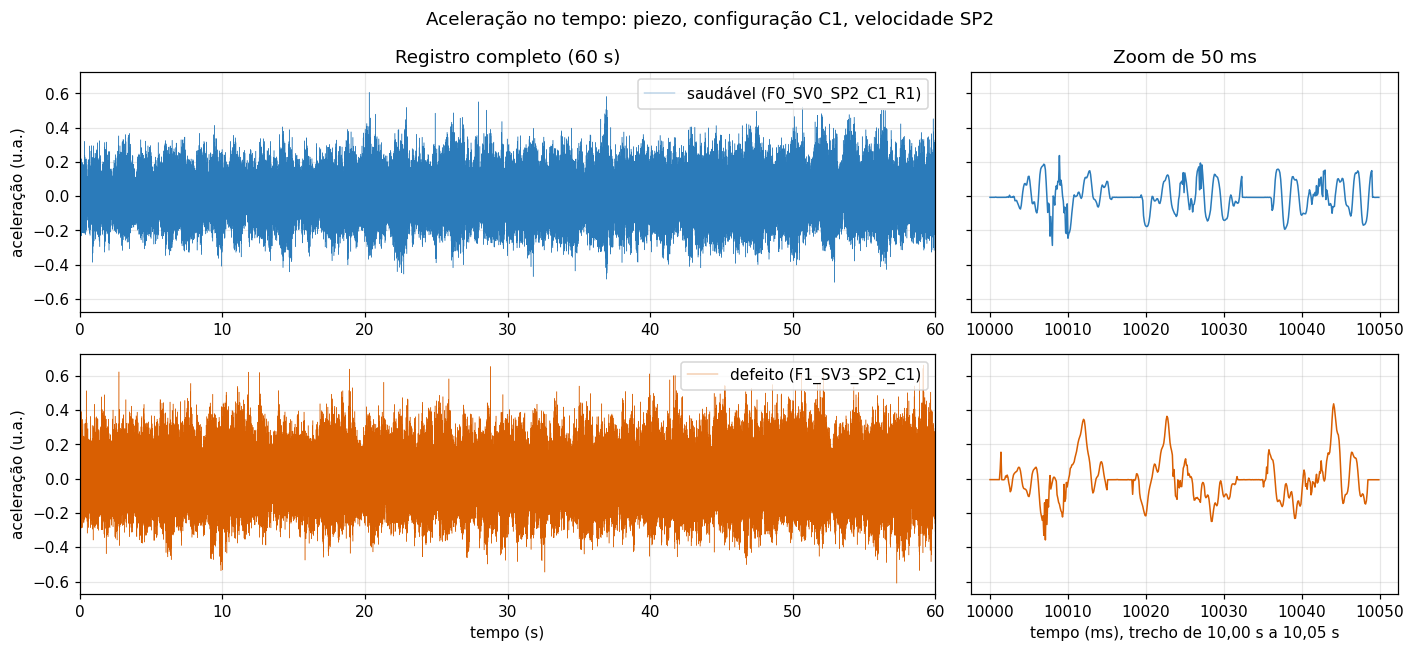

In [11]:
SAUDAVEL_EX, DEFEITO_EX = 'F0_SV0_SP2_C1_R1', 'F1_SV3_SP2_C1'   # mesma data, mesma velocidade

fig, axes = plt.subplots(2, 2, figsize=(13, 6), sharey=True, gridspec_kw={'width_ratios': [2, 1]})
for linha, (rid, classe) in enumerate([(SAUDAVEL_EX, 'saudável'), (DEFEITO_EX, 'defeito')]):
    x = sinais[rid]
    t = np.arange(len(x)) / FS
    axes[linha, 0].plot(t, x, color=CORES[classe], lw=0.3, label=f'{classe} ({rid})')
    axes[linha, 0].set_xlim(0, 60)
    trecho = (t >= 10) & (t < 10.05)
    axes[linha, 1].plot(t[trecho] * 1000, x[trecho], color=CORES[classe], lw=1)
    axes[linha, 0].set_ylabel('aceleração (u.a.)')
    axes[linha, 0].legend(loc='upper right')
axes[1, 0].set_xlabel('tempo (s)')
axes[1, 1].set_xlabel('tempo (ms), trecho de 10,00 s a 10,05 s')
axes[0, 0].set_title('Registro completo (60 s)')
axes[0, 1].set_title('Zoom de 50 ms')
fig.suptitle('Aceleração no tempo: piezo, configuração C1, velocidade SP2')
plt.tight_layout(); plt.show()

No registro de 60 s, os dois sinais têm amplitude estável (cerca de ±0,6 u.a.) e não dá para dizer qual hélice tem defeito. No zoom aparecem rajadas a cada 10 ms, aproximadamente o período de uma volta em SP2 (98 Hz, confirmado em 3.3). No defeituoso as rajadas mudam de forma e surgem picos isolados maiores, mas a diferença é difícil de medir a olho. Por isso calculamos características por janela e passamos para a frequência em 3.3.

### 3.2.2 Características temporais

Para cada janela $x[n]$, $n = 0, \dots, N-1$:

| característica | definição | unidade | interpretação |
|---|---|---|---|
| média | $\bar{x} = \frac{1}{N}\sum_n x[n]$ | u.a. | nível DC (offset do sensor) |
| potência média | $P = \frac{1}{N}\sum_n x[n]^2$ | u.a.² | média temporal de $x^2$ |
| RMS | $x_{rms} = \sqrt{P}$ | u.a. | intensidade eficaz da vibração |
| desvio padrão | $\sigma = \sqrt{\frac{1}{N}\sum_n (x[n]-\bar{x})^2}$ | u.a. | oscilação em torno da média |
| pico absoluto | $\max_n \lvert x[n] \rvert$ | u.a. | maior excursão instantânea |
| pico a pico | $\max_n x[n] - \min_n x[n]$ | u.a. | excursão total |
| fator de crista | $\max_n \lvert x[n] \rvert \,/\, x_{rms}$ | adimensional | quão impulsivo é o sinal (senoide: $\sqrt{2} \approx 1{,}41$) |

A potência média é a versão discreta, numa janela, de $P_x = \lim_{T\to\infty} \frac{1}{2T}\int_{-T}^{T} \lvert x(t) \rvert^2\,dt$:

> "A média da energia do sinal ao longo do tempo é a potência do sinal." (Lecture 2, slide 42)

A média é o coeficiente DC $D_0$ da série de Fourier, "a média temporal do sinal" (Lecture 8, slide 28).

In [12]:
def caracteristicas_tempo(x):
    rms = np.sqrt(np.mean(x ** 2))
    pico = np.max(np.abs(x))
    return {'média': np.mean(x),
            'RMS': rms,
            'potência média': np.mean(x ** 2),
            'desvio padrão': np.std(x),
            'pico absoluto': pico,
            'pico a pico': np.max(x) - np.min(x),
            'fator de crista': pico / rms}

feat_tempo = pd.DataFrame([caracteristicas_tempo(j) for j in janelas])
COLS_TEMPO = list(feat_tempo.columns)
df = pd.concat([meta, feat_tempo], axis=1)
df[['id', 'janela', 'classe', 'SP'] + COLS_TEMPO].head()

,id,janela,classe,SP,média,RMS,potência média,desvio padrão,pico absoluto,pico a pico,fator de crista
0,F0_SV0_SP1_C1_R1,0,saudável,SP1,-0.0007217,0.04994,0.002494,0.04993,0.237,0.4718,4.746
1,F0_SV0_SP1_C1_R1,1,saudável,SP1,-0.001081,0.03818,0.001457,0.03816,0.1654,0.2901,4.333
2,F0_SV0_SP1_C1_R1,2,saudável,SP1,-0.0007202,0.04481,0.002008,0.04481,0.1951,0.3532,4.354
3,F0_SV0_SP1_C1_R1,3,saudável,SP1,-0.0003827,0.04783,0.002288,0.04783,0.1993,0.3679,4.167
4,F0_SV0_SP1_C1_R1,4,saudável,SP1,-0.001551,0.04527,0.002049,0.04524,0.1888,0.3752,4.17


### 3.2.3 Tabela e gráficos comparativos

Média e desvio padrão de cada característica por velocidade e classe (a tabela com uma linha por janela é o `df`), seguidas dos boxplots de RMS, desvio padrão, pico absoluto e fator de crista e do RMS separado por tipo de falha.

In [13]:
resumo_tempo = df.groupby(['SP', 'classe'])[COLS_TEMPO].agg(['mean', 'std'])
resumo_tempo

média               RMS          potência média            \
                   mean       std    mean      std           mean       std   
SP  classe                                                                    
SP1 defeito   -0.001056 0.0002627 0.02502 0.004474      0.0006458 0.0002344   
    saudável  -0.000769 0.0005195 0.06273  0.01646       0.004204   0.00205   
SP2 defeito   -0.001179 0.0005751 0.09835  0.01548       0.009913  0.003165   
    saudável -0.0009612 0.0006427   0.129   0.0325        0.01769  0.008578   
SP3 defeito   -0.001696  0.001636  0.3046   0.1186         0.1068   0.07998   
    saudável  -0.001439  0.001248  0.2729   0.0495        0.07691    0.0264   

             desvio padrão          pico absoluto         pico a pico          \
                      mean      std          mean     std        mean     std   
SP  classe                                                                      
SP1 defeito        0.02499 0.004479        0.1342 0.02183      0.2337 0.03155   
    saudável       0.06272  0.01646        0.2841 0.07958      0.5256  0.1422   
SP2 defeito        0.09834  0.01548        0.4433 0.07611       0.816   0.122   
    saudável         0.129   0.0325        0.5522  0.1503       1.011  0.2533   
SP3 defeito         0.3046   0.1186         1.107  0.3558       2.109  0.6849   
    saudável        0.2729   0.0495         1.008  0.2041       1.886    0.38   

             fator de crista         
                        mean    std  
SP  classe                           
SP1 defeito            5.429 0.7309  
    saudável           4.555  0.606  
SP2 defeito            4.524 0.4967  
    saudável           4.302 0.5675  
SP3 defeito            3.755 0.5091  
    saudável           3.708 0.4433

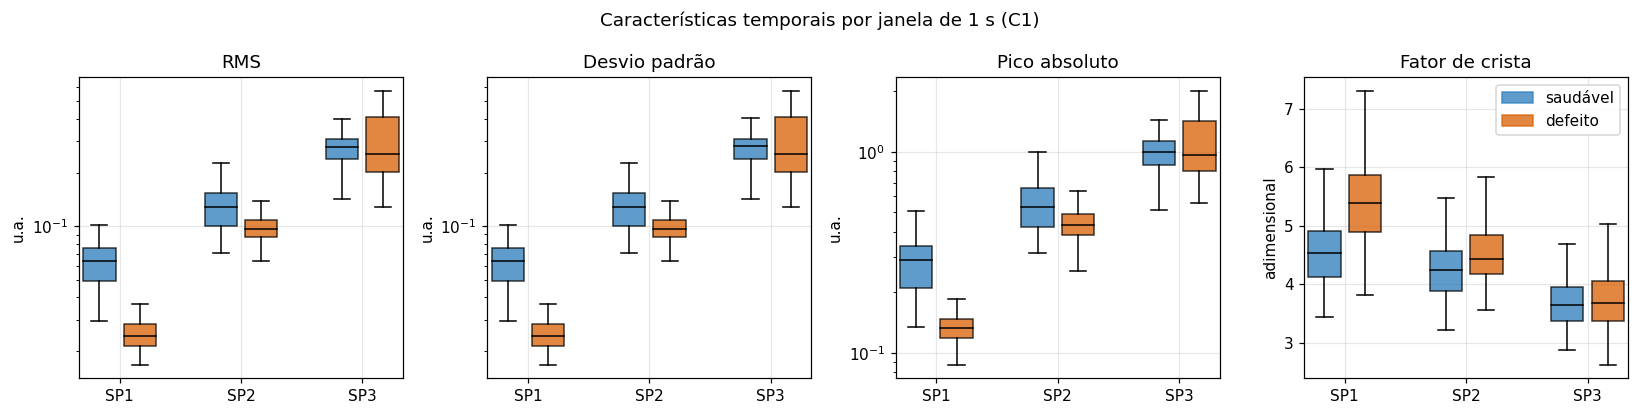

In [14]:
def boxplot_por_velocidade(ax, dados, coluna, titulo, ylabel, log=False):
    """Boxplots lado a lado (saudável e defeito) para cada velocidade."""
    for i, sp in enumerate(VELOCIDADES):
        for j, (classe, cor) in enumerate(CORES.items()):
            valores = dados.loc[(dados['SP'] == sp) & (dados['classe'] == classe), coluna]
            b = ax.boxplot(valores, positions=[3 * i + j], widths=0.8, patch_artist=True, showfliers=False)
            b['boxes'][0].set_facecolor(cor); b['boxes'][0].set_alpha(0.75)
            b['medians'][0].set_color('black')
    ax.set_xticks([3 * i + 0.5 for i in range(len(VELOCIDADES))], VELOCIDADES)
    ax.set_title(titulo); ax.set_ylabel(ylabel)
    if log:
        ax.set_yscale('log')

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
boxplot_por_velocidade(axes[0], df, 'RMS', 'RMS', 'u.a.', log=True)
boxplot_por_velocidade(axes[1], df, 'desvio padrão', 'Desvio padrão', 'u.a.', log=True)
boxplot_por_velocidade(axes[2], df, 'pico absoluto', 'Pico absoluto', 'u.a.', log=True)
boxplot_por_velocidade(axes[3], df, 'fator de crista', 'Fator de crista', 'adimensional')
axes[3].legend(handles=[Patch(color=c, label=k, alpha=0.75) for k, c in CORES.items()])
fig.suptitle('Características temporais por janela de 1 s (C1)')
plt.tight_layout(); plt.show()

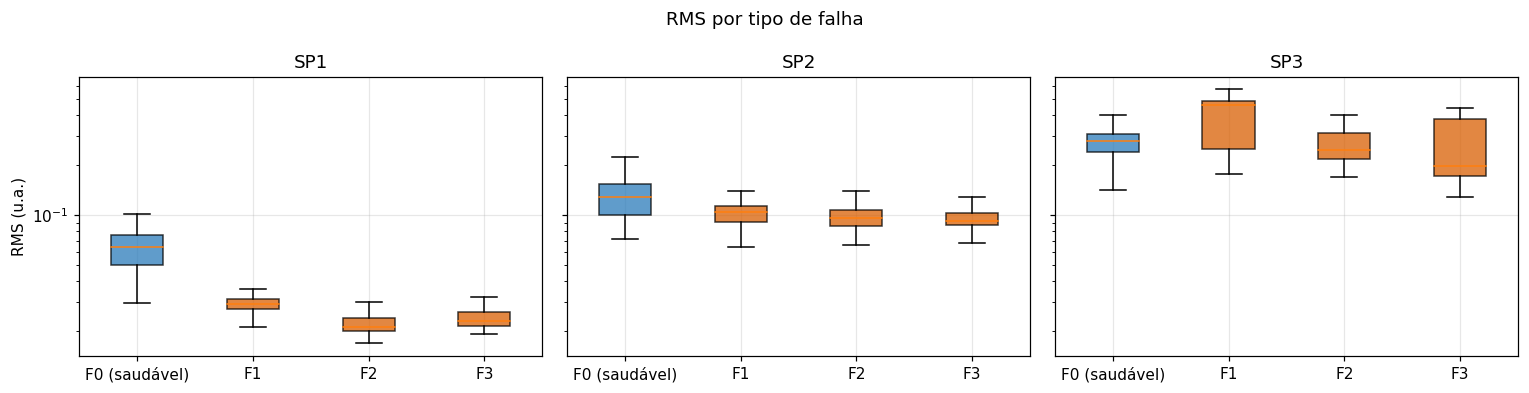

In [15]:
# Mesmo gráfico de RMS, separando os três tipos de falha
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
rotulos = ['F0 (saudável)', 'F1', 'F2', 'F3']
for ax, sp in zip(axes, VELOCIDADES):
    grupos = [df.loc[(df['SP'] == sp) & (df['F'] == f), 'RMS'] for f in range(4)]
    b = ax.boxplot(grupos, patch_artist=True, showfliers=False)
    for caixa, cor in zip(b['boxes'], [CORES['saudável']] + [CORES['defeito']] * 3):
        caixa.set_facecolor(cor); caixa.set_alpha(0.75)
    ax.set_xticks(range(1, 5), rotulos); ax.set_title(sp); ax.set_yscale('log')
axes[0].set_ylabel('RMS (u.a.)')
fig.suptitle('RMS por tipo de falha')
plt.tight_layout(); plt.show()

### 3.2.4 Interpretação

In [16]:
# Relação entre RMS, potência média, média e desvio padrão
erro1 = np.max(np.abs(df['RMS'] ** 2 - df['potência média']))
erro2 = np.max(np.abs(df['RMS'] ** 2 - (df['média'] ** 2 + df['desvio padrão'] ** 2)))
contrib_media = (df['média'] ** 2 / df['potência média'])
print(f'max |RMS² - potência média|        = {erro1:.2e}')
print(f'max |RMS² - (média² + desvio²)|    = {erro2:.2e}')
print(f'fração da potência devida à média: mediana {100 * contrib_media.median():.3f} %, máximo {100 * contrib_media.max():.3f} %')

max |RMS² - potência média|        = 5.55e-17
max |RMS² - (média² + desvio²)|    = 1.11e-16
fração da potência devida à média: mediana 0.013 %, máximo 0.657 %


A relação entre RMS, potência e média vem do teorema de Parseval:

> "A potência do sinal no domínio do tempo é igual à soma das potências das componentes no domínio da frequência." (Lecture 8, slide 27)

Separando o termo DC ($\lvert D_0 \rvert^2 = \bar{x}^2$) dos demais, que somam a variância, obtemos $P = x_{rms}^2 = \bar{x}^2 + \sigma^2$, confirmado acima com erro de $10^{-16}$. Respostas aos itens de 3.2.4:

- **RMS e potência média** carregam a mesma informação, porque uma é o quadrado da outra.
- **Efeito da média:** ela responde por no máximo 0,66 % da potência, então RMS e desvio padrão praticamente coincidem. Com um offset grande, o RMS seria inflado por um nível constante que não é vibração, e o desvio padrão seria a medida adequada. A média não distingue as condições.
- **O que difere entre as condições:** a intensidade depende mais da velocidade (o RMS cresce de 4 a 12 vezes de SP1 a SP3) do que da condição, e o defeito não vibra mais. O saudável tem RMS 2,5 vezes maior em SP1 (0,063 contra 0,025 u.a.), um pouco maior em SP2 (0,129 contra 0,098 u.a.), e as classes se sobrepõem em SP3 (0,273 contra 0,305 u.a.). O saudável R1, do mesmo dia dos defeituosos, também vibra mais em SP1.
- **Fator de crista:** maior no defeito, sobretudo em SP1 (5,4 contra 4,6), o que indica um sinal mais impulsivo, independentemente da escala.
- **Tipos de falha:** F1, F2 e F3 se parecem em SP1 e SP2; em SP3, F1 tem RMS maior.
- **Redundância:** RMS, potência, desvio padrão, pico e pico a pico medem a escala do sinal (quantificado em 3.4); o fator de crista é a única medida temporal ligada à forma.

## 3.3 Análise no domínio da frequência

### 3.3.1 FFT, eixo de frequências e normalização

Uma janela de duração $T_0 = N/f_s$ pode ser escrita como série de Fourier com $\omega_0 = 2\pi/T_0$:

> "Se f(t) (...) é definido apenas em um intervalo de comprimento $T_0$ (isto é, de duração finita, que é repetido a cada $T_0$ segundos), então f(t) pode ser escrito como uma série de Fourier." (Lecture 8, slide 4)

Calculando os coeficientes a partir das amostras, $D_k \approx X[k]/N$, onde $X[k] = \sum_{n=0}^{N-1} x[n]\,e^{-j2\pi kn/N}$ é a DFT calculada pela FFT (dedução no relatório, seção 4.1). Daí saem as convenções usadas:

- **eixo:** $f_k = k f_s/N$, com $\Delta f = f_s/N$; usamos só $0 \le f \le f_s/2$, porque o sinal é real e porque, pelo critério de Nyquist (3.3.7), só essa faixa é representada sem ambiguidade (`rfft` e `rfftfreq`);
- **amplitude:** $A[k] = 2\lvert X[k] \rvert/N$, que devolve a amplitude $a$ de uma senoide $a\cos(2\pi f_k t)$;
- **potência por raia:** $P[k] = 2\lvert X[k] \rvert^2/N^2$ (sem o 2 em $k = 0$ e em $f_s/2$), de modo que $\sum_k P[k] = \sigma^2$ por Parseval;
- a média da janela é removida antes, e usamos janela retangular para manter Parseval exato.

In [17]:
def espectro(x, fs):
    """Espectro unilateral de um trecho de N amostras.
    Retorna f (Hz), amplitude A (u.a.) e potência P (u.a.²) por raia.
      - a média do trecho é removida antes (componente DC);
      - f_k = k * fs / N, k = 0..N/2, logo Δf = fs / N;
      - A = 2|X|/N (amplitude de pico de uma senoide naquela raia);
      - P = 2|X|²/N² nas raias que têm par negativo (|X|²/N² em k = 0 e em Nyquist),
        de modo que ΣP = potência do trecho sem DC (Parseval).
    """
    x = x - np.mean(x)
    N = len(x)
    X = np.fft.rfft(x)
    f = np.fft.rfftfreq(N, d=1 / fs)
    A = 2 * np.abs(X) / N
    P = np.abs(X) ** 2 / N ** 2
    P[1:] *= 2
    if N % 2 == 0:          # a raia de Nyquist não tem par
        A[-1] /= 2; P[-1] /= 2
    return f, A, P

# Conferência pelo teorema de Parseval em uma janela
f, A, P = espectro(janelas[0], FS)
print(f'Δf = fs/N = {FS}/{N_JAN} = {f[1]:.2f} Hz | raias: {len(f)} (0 a {f[-1]:.0f} Hz)')
print(f'ΣP = {P.sum():.6e}   variância da janela = {np.var(janelas[0]):.6e}')

Δf = fs/N = 10000/10000 = 1.00 Hz | raias: 5001 (0 a 5000 Hz)
ΣP = 2.493058e-03   variância da janela = 2.493058e-03


Com $N = 10.000$, temos $\Delta f = 1$ Hz e 5.001 raias de 0 a 5 kHz, e $\sum_k P[k]$ coincide com a variância da janela, o que valida a normalização.

### 3.3.2 Espectros comparativos

Média dos espectros das 60 janelas de cada registro, para reduzir a flutuação entre janelas. Saudável R1 contra os três defeitos em SV3, todos em SP2 e do mesmo dia; escalas iguais em cada coluna.

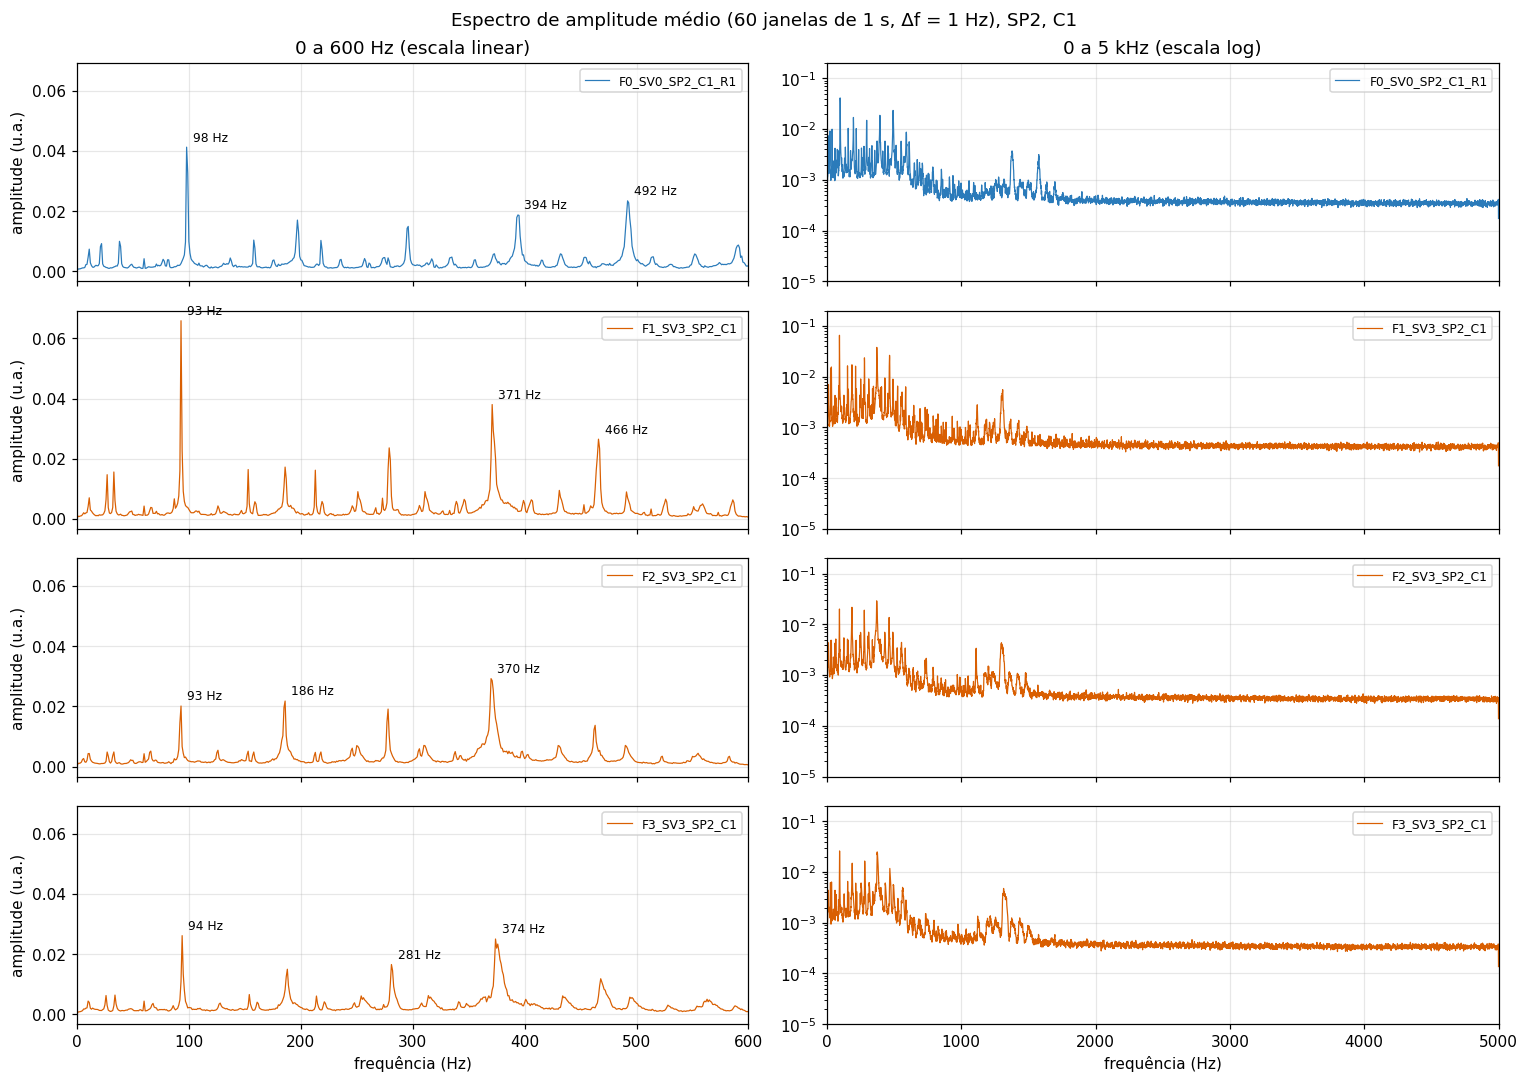

In [18]:
def espectro_medio(rid):
    """Média dos espectros de amplitude das janelas de 1 s de um registro."""
    J = janelar(sinais[rid], N_JAN)
    A = np.mean([espectro(j, FS)[1] for j in J], axis=0)
    return espectro(J[0], FS)[0], A

def marcar_picos(ax, f, A, n=3, fmin=20, distancia=15, cor='k'):
    """Anota os n maiores picos (separados por pelo menos `distancia` Hz)."""
    escolhidos = []
    for i in np.argsort(A)[::-1]:
        if f[i] < fmin or any(abs(f[i] - f[j]) < distancia for j in escolhidos):
            continue
        escolhidos.append(i)
        ax.annotate(f'{f[i]:.0f} Hz', (f[i], A[i]), textcoords='offset points', xytext=(4, 4), fontsize=8, color=cor)
        if len(escolhidos) == n:
            break
    return [f[i] for i in escolhidos]

comparacoes = [(SAUDAVEL_EX, 'saudável'), ('F1_SV3_SP2_C1', 'defeito'), ('F2_SV3_SP2_C1', 'defeito'), ('F3_SV3_SP2_C1', 'defeito')]
fig, axes = plt.subplots(len(comparacoes), 2, figsize=(14, 10), sharex='col', sharey='col')
for linha, (rid, classe) in enumerate(comparacoes):
    f, A = espectro_medio(rid)
    for col, fmax in enumerate([600, FS / 2]):
        ax = axes[linha, col]
        ax.plot(f, A, color=CORES[classe], lw=0.8, label=rid)
        ax.set_xlim(0, fmax)
        if col == 0:
            marcar_picos(ax, f, A)
            ax.set_ylabel('amplitude (u.a.)')
        else:
            ax.set_yscale('log'); ax.set_ylim(1e-5, 0.2)
        ax.legend(loc='upper right', fontsize=8)
axes[0, 0].set_title('0 a 600 Hz (escala linear)')
axes[0, 1].set_title('0 a 5 kHz (escala log)')
axes[-1, 0].set_xlabel('frequência (Hz)'); axes[-1, 1].set_xlabel('frequência (Hz)')
fig.suptitle('Espectro de amplitude médio (60 janelas de 1 s, Δf = 1 Hz), SP2, C1')
plt.tight_layout(); plt.show()

Principais componentes:

- **saudável:** pico em 98 Hz, que interpretamos como a rotação (cerca de 5.900 rpm, coerente com as rajadas de 10 ms), e harmônicos em 197, 296, 394 e 492 Hz;
- **defeitos:** mesma estrutura deslocada para baixo (93 a 94, 186, 279 a 281 e 370 a 374 Hz), ou seja, cerca de 5 % mais devagar;
- **alturas:** no saudável domina o primeiro harmônico; em F2 e F3 o quarto é tão alto quanto o primeiro ou mais; em F1 o primeiro cresce;
- acima de 2 kHz, um patamar de ruído igual em todas as condições.

Um sinal com período $T_{rot}$ tem transformada formada só por impulsos em $n\omega_0$, com $\omega_0 = 2\pi f_{rot}$ (Lecture 13, slide 4), e "a transformada de Fourier do sinal periódico é a transformada de Fourier amostrada de um período" (Lecture 13, slide 15). As posições dos picos dependem, portanto, só da rotação, e as alturas, da forma da vibração em uma volta; como as alturas relativas mudam com o defeito, o defeito muda essa forma. Não atribuímos causa física aos picos que não são múltiplos da rotação.

### 3.3.3 Características espectrais

Para cada janela, com a média removida e as convenções de 3.3.1:

| característica | definição | unidade |
|---|---|---|
| frequência dominante | $f_{k^*}$, com $k^* = \arg\max_{k \geq 1} A[k]$ | Hz |
| magnitude do pico dominante | $A[k^*]$ | u.a. |
| potência na banda $[f_1, f_2)$ | $\sum_{f_1 \le f_k < f_2} P[k]$ | u.a.² |
| centroide espectral | $\sum_k f_k P[k] \,/\, \sum_k P[k]$ (centro de massa do espectro) | Hz |
| entropia espectral | $-\sum_k p_k \log_2 p_k \,/\, \log_2 K$, com $p_k = P[k]/\sum_j P[j]$ e $K$ raias (0: uma raia só; 1: potência espalhada igualmente) | adimensional |

Bandas, escolhidas a partir dos espectros de 3.3.2:

- **B1, 0 a 200 Hz:** a rotação nas três velocidades;
- **B2, 200 a 500 Hz:** harmônicos de ordem 2 a 5, onde aparecem as diferenças de forma;
- **B3, 500 a 2.000 Hz:** harmônicos altos e componentes de banda larga;
- **B4, 2.000 a 5.000 Hz:** praticamente ruído de fundo, usada como referência.

As quatro cobrem todo o espectro, então devem somar $\sigma^2$, o que conferimos abaixo.

In [19]:
BANDAS = {'P banda 1 (0 a 200 Hz)': (0, 200),
          'P banda 2 (200 a 500 Hz)': (200, 500),
          'P banda 3 (500 a 2000 Hz)': (500, 2000),
          'P banda 4 (2000 a 5000 Hz)': (2000, 5001)}

def caracteristicas_freq(x, fs):
    f, A, P = espectro(x, fs)
    k = np.argmax(A[1:]) + 1                 # ignora a raia DC (já removida)
    p = P / P.sum()                          # distribuição normalizada de potência
    p_pos = p[p > 0]
    c = {'freq. dominante (Hz)': f[k],
         'magnitude do pico': A[k],
         'centroide espectral (Hz)': np.sum(f * P) / np.sum(P),
         'entropia espectral': -np.sum(p_pos * np.log2(p_pos)) / np.log2(len(p))}
    for nome, (f1, f2) in BANDAS.items():
        c[nome] = P[(f >= f1) & (f < f2)].sum()
    return c

feat_freq = pd.DataFrame([caracteristicas_freq(j, FS) for j in janelas])
COLS_FREQ = list(feat_freq.columns)
df = pd.concat([df, feat_freq], axis=1)
df[['id', 'janela', 'classe', 'SP'] + COLS_FREQ].head()

,id,janela,classe,SP,freq. dominante (Hz),magnitude do pico,centroide espectral (Hz),entropia espectral,P banda 1 (0 a 200 Hz),P banda 2 (200 a 500 Hz),P banda 3 (500 a 2000 Hz),P banda 4 (2000 a 5000 Hz)
0,F0_SV0_SP1_C1_R1,0,saudável,SP1,56,0.03686,296.7,0.4633,0.00177,0.0005005,0.0001298,9.241e-05
1,F0_SV0_SP1_C1_R1,1,saudável,SP1,56,0.03043,330.1,0.5092,0.0009954,0.0002762,0.0001237,6.1e-05
2,F0_SV0_SP1_C1_R1,2,saudável,SP1,56,0.03797,313.1,0.4546,0.001363,0.0004407,0.0001263,7.794e-05
3,F0_SV0_SP1_C1_R1,3,saudável,SP1,56,0.03737,313.9,0.4668,0.00154,0.0005322,0.0001268,8.905e-05
4,F0_SV0_SP1_C1_R1,4,saudável,SP1,56,0.03848,296.3,0.4696,0.00142,0.0004351,0.0001119,7.987e-05


In [20]:
# As bandas cobrem todo o espectro: a soma das 4 potências deve ser igual à variância da janela
soma_bandas = df[list(BANDAS)].sum(axis=1)
print(f'max |Σ bandas - desvio²| / desvio² = {np.max(np.abs(soma_bandas - df["desvio padrão"]**2) / df["desvio padrão"]**2):.1e}')

max |Σ bandas - desvio²| / desvio² = 6.6e-16


Erro relativo da ordem de $10^{-15}$: as convenções do tempo e da frequência são coerentes.

### 3.3.4 Tabela e gráficos comparativos

Média e desvio padrão por velocidade e classe, boxplots das características espectrais e mediana da potência em cada banda.

In [21]:
resumo_freq = df.groupby(['SP', 'classe'])[COLS_FREQ].agg(['mean', 'std'])
resumo_freq

freq. dominante (Hz)       magnitude do pico           \
                             mean   std              mean      std   
SP  classe                                                           
SP1 defeito                 134.9 112.8           0.01464 0.007072   
    saudável                138.8 95.03           0.03986  0.01224   
SP2 defeito                 281.6 132.3           0.05159  0.01612   
    saudável                244.2 114.2           0.07881  0.02988   
SP3 defeito                 249.3 125.9            0.2218   0.1201   
    saudável                239.2 129.4            0.2016  0.05857   

             centroide espectral (Hz)       entropia espectral          \
                                 mean   std               mean     std   
SP  classe                                                               
SP1 defeito                     479.8 93.54              0.613 0.07632   
    saudável                    338.4 37.19             0.5025 0.04679   
SP2 defeito                     462.1  41.7             0.5585 0.04148   
    saudável                      410 46.78              0.515 0.05384   
SP3 defeito                     367.5 59.69             0.4364 0.06094   
    saudável                    355.2 48.93             0.4323 0.07052   

             P banda 1 (0 a 200 Hz)           P banda 2 (200 a 500 Hz)  \
                               mean       std                     mean   
SP  classe                                                               
SP1 defeito               0.0003222 0.0002135                 0.000222   
    saudável               0.001443 0.0007841                 0.002472   
SP2 defeito                0.002597  0.001385                 0.005997   
    saudável               0.004616  0.001982                  0.01153   
SP3 defeito                 0.04697   0.05175                  0.05324   
    saudável                0.03477   0.02073                  0.03622   

                       P banda 3 (500 a 2000 Hz)            \
                   std                      mean       std   
SP  classe                                                   
SP1 defeito  7.858e-05                 6.217e-05 1.106e-05   
    saudável  0.001634                 0.0001529 3.709e-05   
SP2 defeito   0.002178                  0.001042 0.0002514   
    saudável  0.007194                   0.00108 0.0002741   
SP3 defeito    0.03374                  0.004585  0.002997   
    saudável   0.01721                  0.004252  0.001027   

             P banda 4 (2000 a 5000 Hz)            
                                   mean       std  
SP  classe                                         
SP1 defeito                   3.817e-05 6.849e-06  
    saudável                  0.0001356 5.406e-05  
SP2 defeito                   0.0002753 7.738e-05  
    saudável                  0.0004634 0.0001996  
SP3 defeito                    0.002023  0.001251  
    saudável                   0.001658 0.0004782

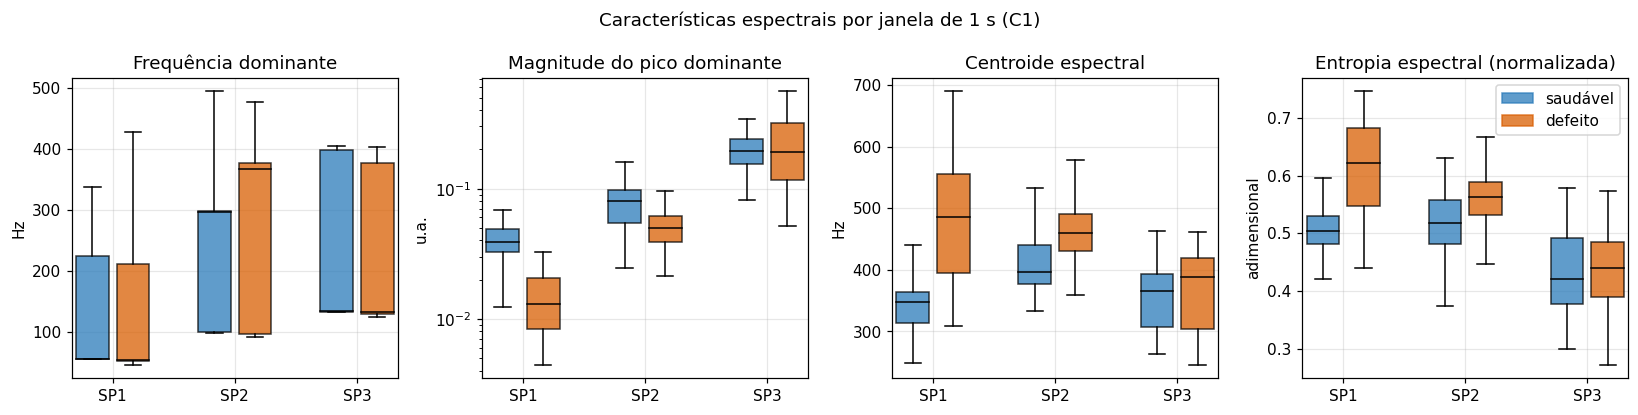

In [22]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
boxplot_por_velocidade(axes[0], df, 'freq. dominante (Hz)', 'Frequência dominante', 'Hz')
boxplot_por_velocidade(axes[1], df, 'magnitude do pico', 'Magnitude do pico dominante', 'u.a.', log=True)
boxplot_por_velocidade(axes[2], df, 'centroide espectral (Hz)', 'Centroide espectral', 'Hz')
boxplot_por_velocidade(axes[3], df, 'entropia espectral', 'Entropia espectral (normalizada)', 'adimensional')
axes[3].legend(handles=[Patch(color=c, label=k, alpha=0.75) for k, c in CORES.items()])
fig.suptitle('Características espectrais por janela de 1 s (C1)')
plt.tight_layout(); plt.show()

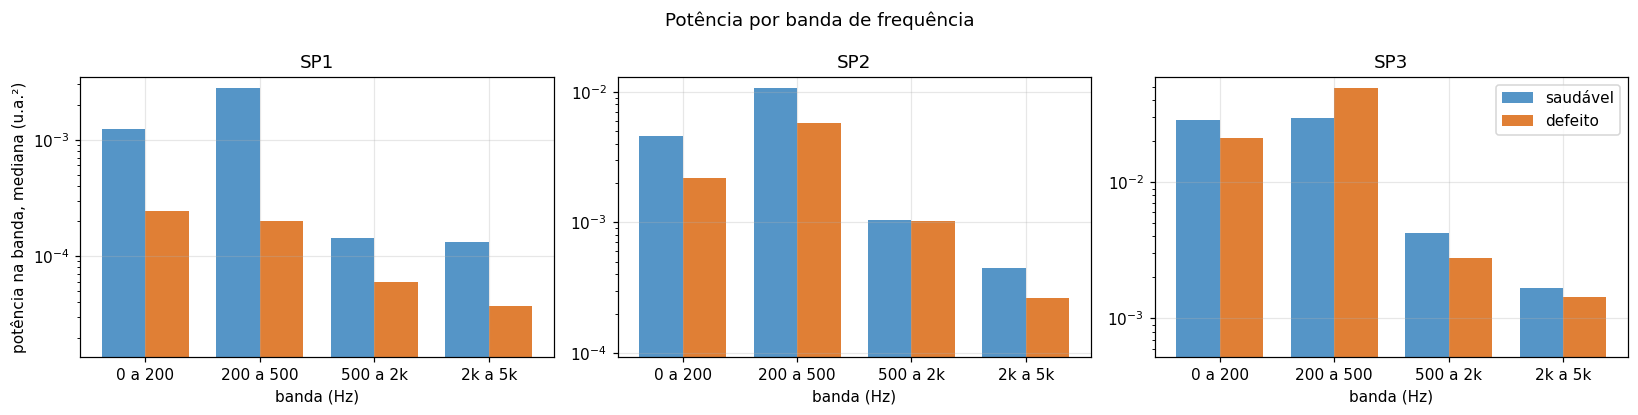

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))   # escala própria em cada painel (SP1 tem potências bem menores)
nomes_bandas = list(BANDAS)
largura = 0.38
for ax, sp in zip(axes, VELOCIDADES):
    for j, (classe, cor) in enumerate(CORES.items()):
        med = df.loc[(df['SP'] == sp) & (df['classe'] == classe), nomes_bandas].median()
        ax.bar(np.arange(len(nomes_bandas)) + (j - 0.5) * largura, med, largura, color=cor, alpha=0.8, label=classe)
    ax.set_xticks(range(len(nomes_bandas)), ['0 a 200', '200 a 500', '500 a 2k', '2k a 5k'])
    ax.set_yscale('log'); ax.set_title(sp); ax.set_xlabel('banda (Hz)')
    ax.set_ylim(bottom=df.loc[df['SP'] == sp, nomes_bandas].median().min() / 3)
axes[0].set_ylabel('potência na banda, mediana (u.a.²)')
axes[-1].legend()
fig.suptitle('Potência por banda de frequência')
plt.tight_layout(); plt.show()

### 3.3.5 Interpretação dos espectros

- **Picos relevantes:** rotação e harmônicos até a sexta ordem, com a rotação em cerca de 56, 98 e 133 Hz no saudável e um pouco abaixo no defeito (3.6).
- **Frequência dominante:** salta entre harmônicos de uma janela para outra (boxplot bimodal) e, sozinha, separa mal as classes.
- **Centroide e entropia:** maiores no defeito em SP1 (480 contra 338 Hz; 0,61 contra 0,50) e em SP2 (462 contra 410 Hz; 0,56 contra 0,52), ou seja, a potência fica mais espalhada pelos harmônicos. Em SP3 as classes se sobrepõem.
- **Bandas:** o saudável tem mais potência em todas as bandas em SP1 e em quase todas em SP2, coerente com o RMS; em SP3, o defeito só tem mais potência na B2.

O espectro revela três coisas que o gráfico temporal não mostra:

1. a vibração é composta pela rotação e seus harmônicos, e sabemos em quais frequências;
2. a hélice com defeito gira mais devagar na mesma velocidade nominal;
3. o defeito redistribui a potência entre os harmônicos, o que corresponde a uma mudança na forma de cada ciclo.

### 3.3.6 Efeito da duração do trecho (resolução espectral)

FFT de dois trechos do saudável SP2 R1: 0,1 s ($N = 1.000$, $\Delta f = 10$ Hz) e 2 s ($N = 20.000$, $\Delta f = 0{,}5$ Hz). O zoom em torno da rotação inclui também um trecho de 10 s ($\Delta f = 0{,}1$ Hz).

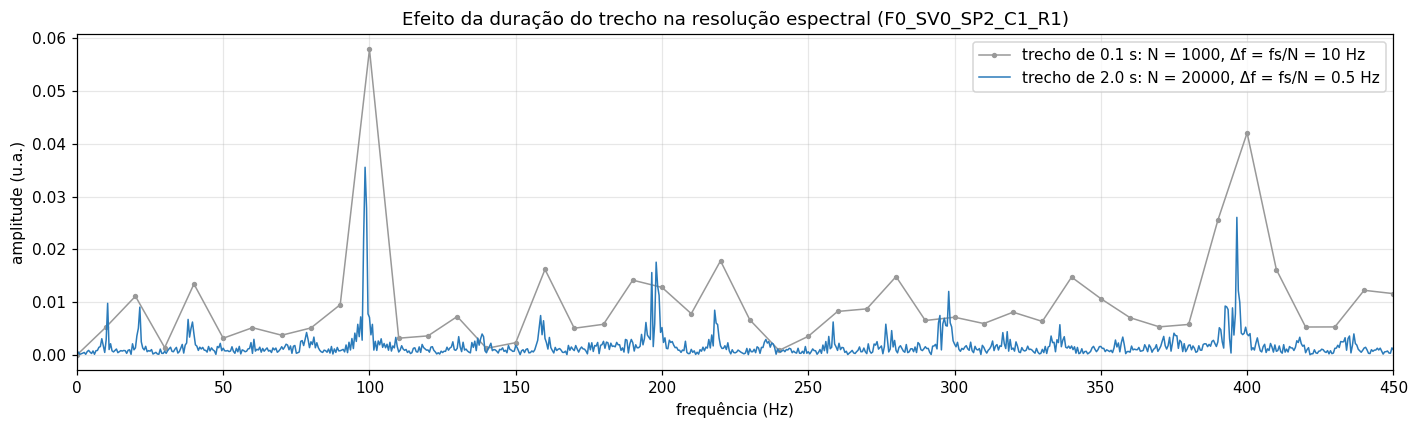

In [24]:
x = sinais[SAUDAVEL_EX]
fig, ax = plt.subplots(figsize=(13, 4))
for dur, cor in [(0.1, '#999999'), (2.0, '#2b7bba')]:
    N = int(dur * FS)
    f, A, _ = espectro(x[:N], FS)
    ax.plot(f, A, '.-' if dur < 1 else '-', color=cor, lw=1, ms=5,
            label=f'trecho de {dur} s: N = {N}, Δf = fs/N = {FS / N:g} Hz')
ax.set_xlim(0, 450)
ax.set_xlabel('frequência (Hz)'); ax.set_ylabel('amplitude (u.a.)')
ax.set_title(f'Efeito da duração do trecho na resolução espectral ({SAUDAVEL_EX})')
ax.legend(); plt.tight_layout(); plt.show()

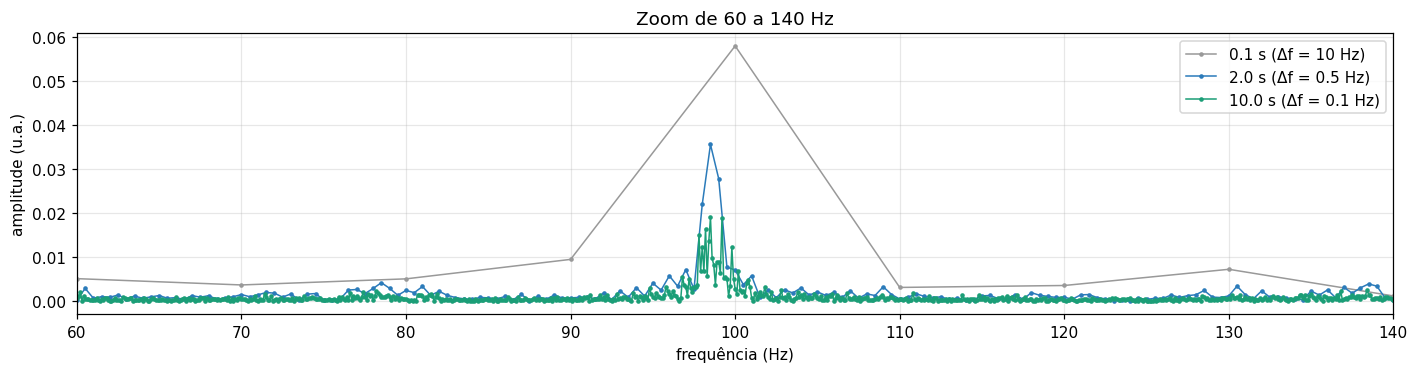

In [25]:
# Zoom em torno da frequência de rotação: duas raias próximas só se separam com Δf pequeno
fig, ax = plt.subplots(figsize=(13, 3.5))
for dur, cor in [(0.1, '#999999'), (2.0, '#2b7bba'), (10.0, '#1b9e77')]:
    N = int(dur * FS)
    f, A, _ = espectro(x[:N], FS)
    ax.plot(f, A, '.-', color=cor, lw=1, ms=4, label=f'{dur} s (Δf = {FS / N:g} Hz)')
ax.set_xlim(60, 140); ax.set_xlabel('frequência (Hz)'); ax.set_ylabel('amplitude (u.a.)')
ax.legend(); ax.set_title('Zoom de 60 a 140 Hz'); plt.tight_layout(); plt.show()

Resultado:

- **0,1 s:** só há raias a cada 10 Hz, então a rotação aparece "em 100 Hz" e o quarto harmônico "em 400 Hz" (os valores reais são 98,5 e 394 Hz), e picos a menos de 10 Hz se fundem;
- **2 s:** a rotação aparece em 98,5 Hz, e picos antes misturados se separam;
- **10 s:** o pico se divide em raias entre 97 e 100 Hz, porque a rotação varia levemente ao longo do trecho.

A FFT trata o trecho de duração $T_0$ como um período de um sinal periódico, cujo espectro são amostras da transformada de um período (Lecture 13, slide 15), espaçadas de $\Delta f = 1/T_0 = f_s/N$; por isso $\Delta f$ depende só da duração do trecho. Trechos curtos também alargam os picos: recortar é multiplicar por um retângulo, cuja transformada é uma sinc (Lecture 10, slide 8), o produto vira convolução na frequência (Lecture 11, slide 3), e a sinc é tanto mais larga quanto mais curto o trecho (Lecture 10, slide 10). A janela de 1 s resolve os cerca de 4 Hz entre saudável e defeito sem que a rotação varie dentro dela.

### 3.3.7 Efeito da amostragem (aliasing)

#### Fundamentação teórica: critério de Nyquist

O critério de Nyquist, usado em 3.1.1, 3.3.1 e nesta seção, vem do teorema da amostragem da Lecture 13, em quatro passos:

1. Amostrar é multiplicar o sinal por um trem de impulsos espaçados de $T$: $x(t)\delta_T(t) = \sum_n x(nT)\,\delta(t - nT)$ (Lecture 13, slide 17).
2. Um produto no tempo vira convolução na frequência (Lecture 11, slide 3), e a transformada de um trem de impulsos é outro trem de impulsos, espaçados de $f_s = 1/T$ (Lecture 13, slide 11).
3. Logo, o espectro amostrado é o original repetido a cada $f_s$: $X_s(j\omega) = \frac{1}{T}\sum_n X\big(j(\omega - n\omega_0)\big)$ (Lecture 13, slide 20).
4. Se o sinal tem componentes até $B$ Hz, as cópias só não se sobrepõem se $f_s > 2B$; a sobreposição é o aliasing (Lecture 13, slides 22 e 23).

> "Não ocorre aliasing somente se $2B < 1/T$ Hz. (...) A taxa de amostragem $2B$ é a taxa de Nyquist de $f(t)$, a menor taxa que permite recuperar $f(t)$ perfeitamente." (Lecture 13, slide 23)

Consequências usadas no projeto: o eixo da FFT vai só até $f_s/2$; uma componente em $f > f_s/2$ reaparece em $\lvert f - m f_s \rvert$ (por exemplo, 403 Hz amostrado a 500 Hz aparece em 97 Hz); e, para reduzir a taxa sem aliasing, é preciso filtrar com um passa-baixas antes de descartar amostras.

#### O experimento

Pegamos 10 s do saudável `F0_SV0_SP3_C1_R1` (picos em 134 e 403 Hz) e reduzimos a taxa de 10 kHz para 500 Hz ($M = 20$; nova frequência de Nyquist de 250 Hz) de duas formas:

1. **sem filtro:** $x_d[n] = x[20n]$ (`x[::20]`), a decimação, que extrai uma amostra a cada 20 e perde as intermediárias (Lecture 2, slide 18);
2. **com filtro anti-aliasing:** `scipy.signal.decimate`, que aplica um passa-baixas antes de descartar amostras.

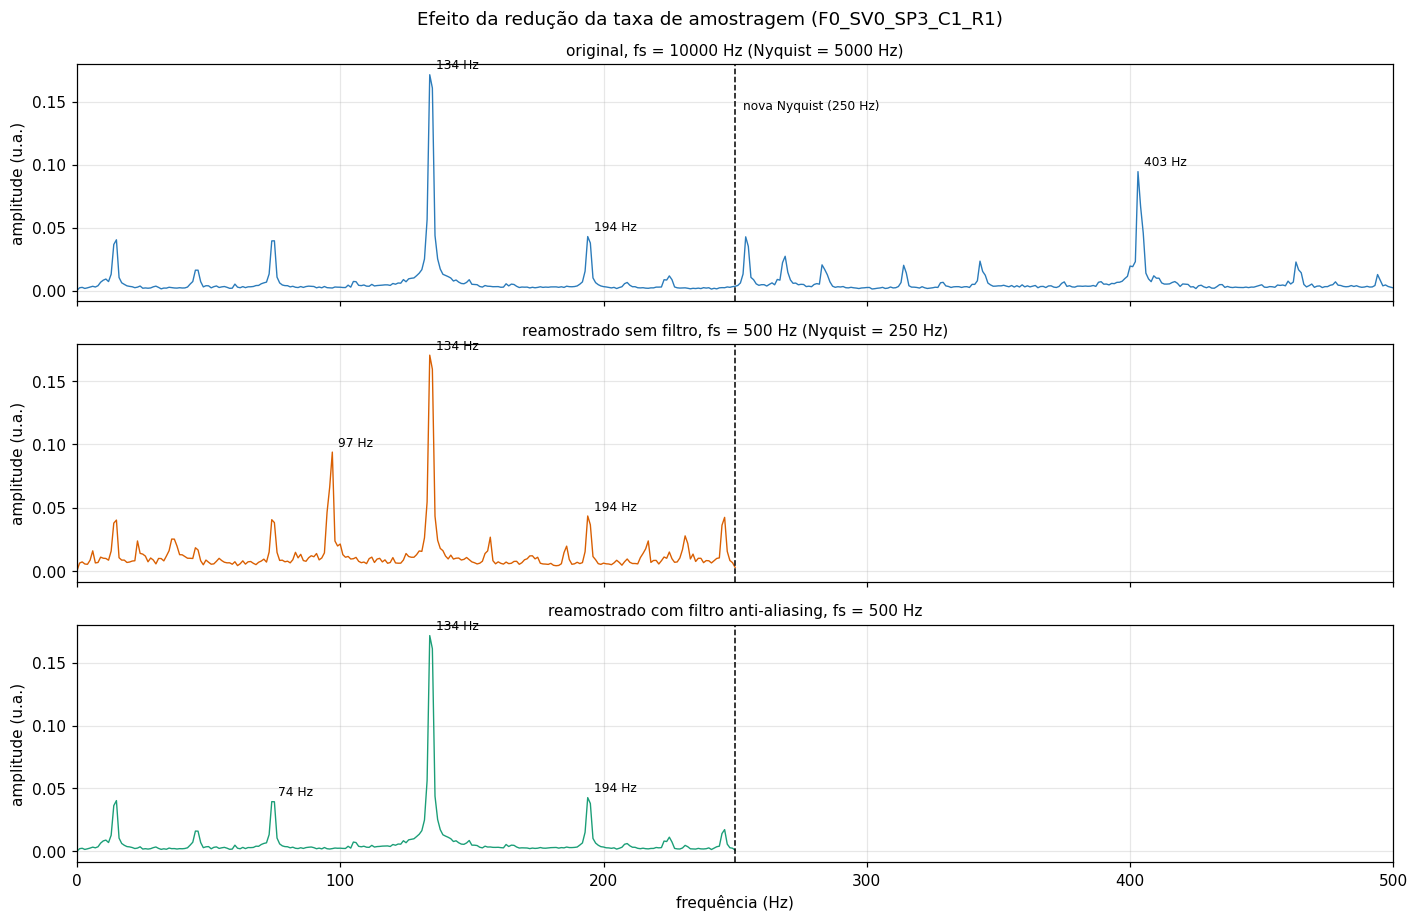

In [26]:
ALIAS_EX = 'F0_SV0_SP3_C1_R1'
M = 20                                   # fator de redução
FS_NOVA = FS // M                        # 500 Hz, Nyquist = 250 Hz
x = sinais[ALIAS_EX][: 10 * FS]          # 10 s de sinal

sem_filtro = x[::M]                                  # x_d[n] = x[M n]: só descarta amostras
com_filtro = decimate(x, M, ftype='fir')             # filtro passa-baixas + descarte

def espectro_longo(sinal, fs, n_seg):
    """Média dos espectros de amplitude em segmentos de n_seg amostras."""
    segs = janelar(sinal, n_seg)
    f = espectro(segs[0], fs)[0]
    return f, np.mean([espectro(s, fs)[1] for s in segs], axis=0)

fig, axes = plt.subplots(3, 1, figsize=(13, 8.5), sharex=True)
casos = [(x, FS, f'original, fs = {FS} Hz (Nyquist = {FS // 2} Hz)', '#2b7bba'),
         (sem_filtro, FS_NOVA, f'reamostrado sem filtro, fs = {FS_NOVA} Hz (Nyquist = {FS_NOVA // 2} Hz)', '#d95f02'),
         (com_filtro, FS_NOVA, f'reamostrado com filtro anti-aliasing, fs = {FS_NOVA} Hz', '#1b9e77')]
for ax, (sinal, fs, titulo, cor) in zip(axes, casos):
    f, A = espectro_longo(sinal, fs, int(fs))          # segmentos de 1 s, Δf = 1 Hz
    ax.plot(f, A, color=cor, lw=0.9)
    marcar_picos(ax, f, A, n=3, fmin=20)
    ax.axvline(FS_NOVA / 2, color='k', ls='--', lw=1)
    ax.set_title(titulo, fontsize=10); ax.set_ylabel('amplitude (u.a.)')
axes[-1].set_xlim(0, 500); axes[-1].set_xlabel('frequência (Hz)')
axes[0].text(FS_NOVA / 2 + 3, axes[0].get_ylim()[1] * 0.8, 'nova Nyquist (250 Hz)', fontsize=8)
fig.suptitle(f'Efeito da redução da taxa de amostragem ({ALIAS_EX})')
plt.tight_layout(); plt.show()

Resultado, à luz do critério de Nyquist ($f_s > 2 f_{max}$):

- **sem filtro:** o terceiro harmônico (403 Hz, acima de 250 Hz) reaparece em $500 - 403 = 97$ Hz, onde o original não tem pico. É uma componente falsa, que poderia ser confundida com a rotação de SP2 (98 Hz). O ruído acima de 250 Hz também é rebatido, e o patamar sobe;
- os picos abaixo de 250 Hz (134 e 194 Hz) continuam no lugar certo;
- **com filtro:** o pico falso some, porque o passa-baixas (Lecture 12, slide 16) atua como $Y(j\omega) = H(j\omega)X(j\omega)$ (Lecture 12, slide 4) e elimina as componentes acima de 250 Hz antes da reamostragem.

Como previsto na fundamentação, a nova taxa só representa sem ambiguidade a faixa de 0 a 250 Hz. Na prática, analisar até o quinto harmônico em SP3 (cerca de 670 Hz) exige $f_s > 1{,}3$ kHz, o que exclui a IMU e justifica o uso do piezo.

## 3.4 Comparação entre os domínios

Para comparar características de unidades diferentes, medimos a distância entre as médias das classes em desvios padrão, usando só a média e o desvio padrão definidos em 3.2.2:

$$d = \frac{\mu_{defeito} - \mu_{saudável}}{\sqrt{(\sigma_{defeito}^2 + \sigma_{saudável}^2)/2}}.$$

Com $d \approx 0$, as classes se sobrepõem; com $\lvert d \rvert$ por volta de 2, quase não se sobrepõem; $d < 0$ indica valor menor no defeito. Calculamos $d$ em cada velocidade e com todas juntas. Para a redundância, usamos a correlação de Spearman, que compara as ordenações das janelas e vale 1 para qualquer relação crescente (como entre RMS e potência).

In [27]:
def separacao(dados, coluna):
    """Distância entre as médias das classes, medida em desvios padrão:
    d = (média_defeito - média_saudável) / sqrt((desvio_defeito² + desvio_saudável²) / 2)."""
    a = dados.loc[dados['classe'] == 'defeito', coluna]
    b = dados.loc[dados['classe'] == 'saudável', coluna]
    return (a.mean() - b.mean()) / np.sqrt((np.var(a) + np.var(b)) / 2)

COLS = [c for c in COLS_TEMPO + COLS_FREQ if c != 'média']
sep = pd.DataFrame({sp: [separacao(df[df['SP'] == sp], c) for c in COLS] for sp in VELOCIDADES}, index=COLS)
sep['todas juntas'] = [separacao(df, c) for c in COLS]
sep['domínio'] = ['tempo' if c in COLS_TEMPO else 'frequência' for c in COLS]
sep['média de |d| nas velocidades'] = sep[VELOCIDADES].abs().mean(axis=1)
sep.sort_values('média de |d| nas velocidades', ascending=False).round(2)

,SP1,SP2,SP3,todas juntas,domínio,média de |d| nas velocidades
desvio padrão,-3.14,-1.21,0.35,-0.1,tempo,1.56
RMS,-3.14,-1.21,0.35,-0.1,tempo,1.56
pico a pico,-2.84,-0.98,0.4,-0.12,tempo,1.41
P banda 4 (2000 a 5000 Hz),-2.53,-1.25,0.39,0.03,frequência,1.39
potência média,-2.45,-1.21,0.5,0.12,tempo,1.38
magnitude do pico,-2.53,-1.14,0.21,-0.11,frequência,1.29
pico absoluto,-2.58,-0.92,0.34,-0.13,tempo,1.28
P banda 2 (200 a 500 Hz),-1.95,-1.04,0.64,0.12,frequência,1.21
P banda 3 (500 a 2000 Hz),-3.32,-0.15,0.15,0.03,frequência,1.21
P banda 1 (0 a 200 Hz),-1.96,-1.18,0.31,0.1,frequência,1.15


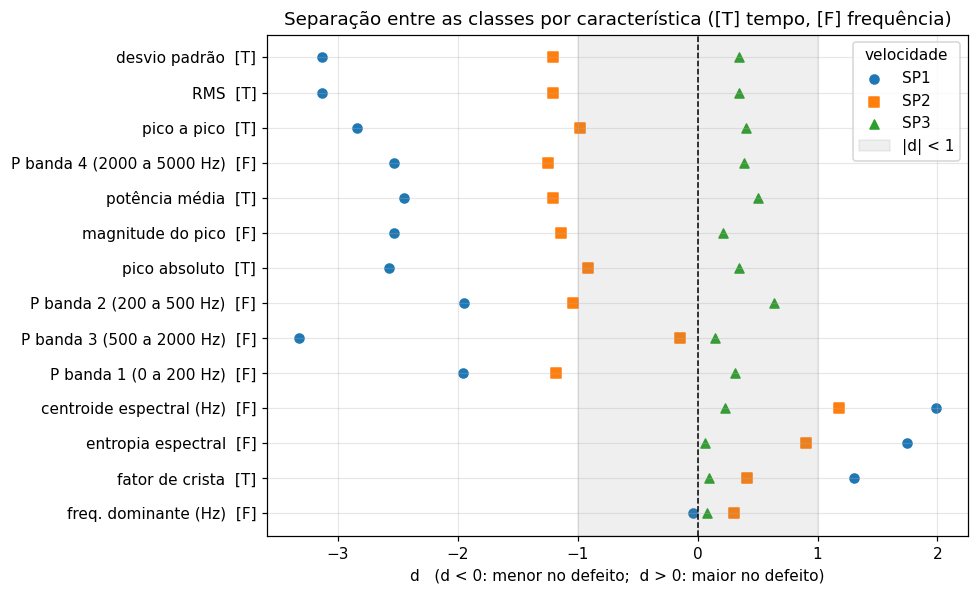

In [28]:
ordem = sep.sort_values('média de |d| nas velocidades').index
fig, ax = plt.subplots(figsize=(9, 5.5))
for i, sp in enumerate(VELOCIDADES):
    ax.scatter(sep.loc[ordem, sp], range(len(ordem)), label=sp, s=35, marker='os^'[i])
ax.axvline(0, color='k', lw=1, ls='--')
ax.axvspan(-1, 1, color='gray', alpha=0.12, label='|d| < 1')
ax.set_yticks(range(len(ordem)), [f"{c}  [{sep.loc[c, 'domínio'][0].upper()}]" for c in ordem])
ax.set_xlabel('d   (d < 0: menor no defeito;  d > 0: maior no defeito)')
ax.legend(title='velocidade')
ax.set_title('Separação entre as classes por característica ([T] tempo, [F] frequência)')
plt.tight_layout(); plt.show()

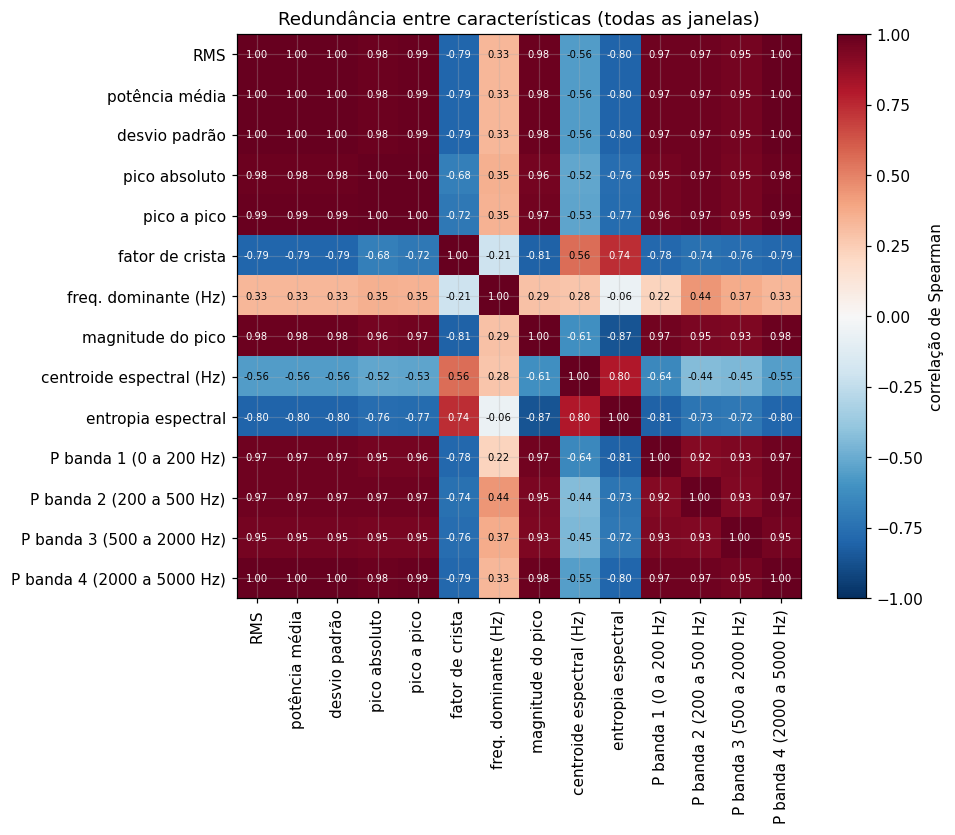

In [29]:
corr = df[COLS].corr(method='spearman')
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(COLS)), COLS, rotation=90); ax.set_yticks(range(len(COLS)), COLS)
for i in range(len(COLS)):
    for j in range(len(COLS)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=6.5,
                color='white' if abs(corr.iloc[i, j]) > 0.6 else 'black')
plt.colorbar(im, label='correlação de Spearman')
ax.set_title('Redundância entre características (todas as janelas)')
plt.tight_layout(); plt.show()

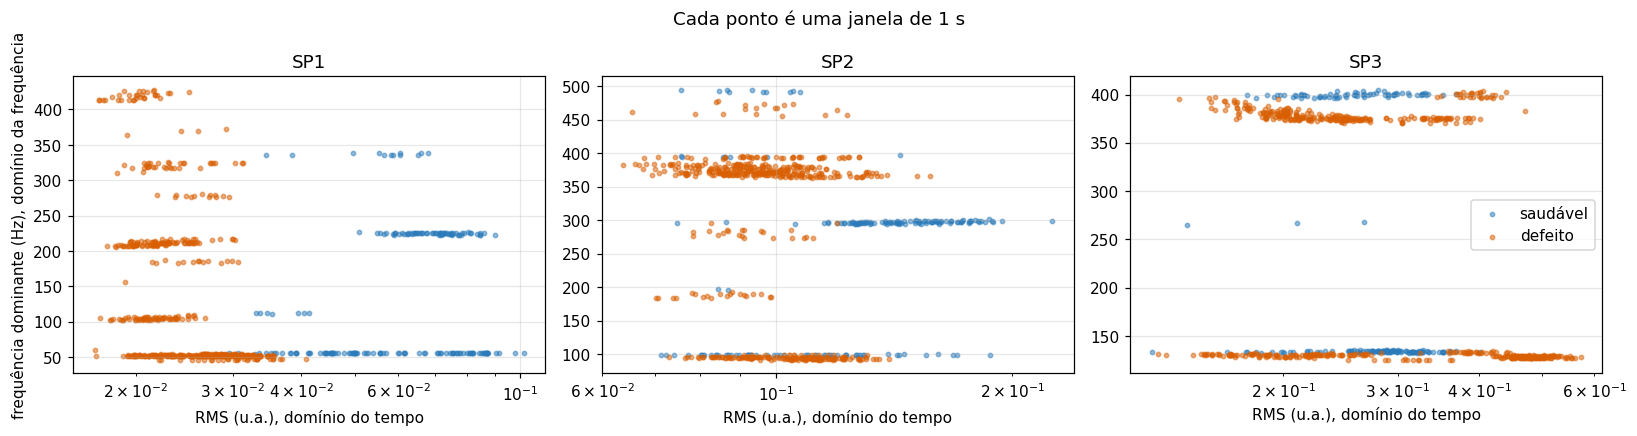

In [30]:
# Mesmos registros nos dois domínios: frequência dominante contra RMS
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, sp in zip(axes, VELOCIDADES):
    for classe, cor in CORES.items():
        d = df[(df['SP'] == sp) & (df['classe'] == classe)]
        ax.scatter(d['RMS'], d['freq. dominante (Hz)'], s=8, alpha=0.5, color=cor, label=classe)
    ax.set_xscale('log'); ax.set_title(sp); ax.set_xlabel('RMS (u.a.), domínio do tempo')
axes[0].set_ylabel('frequência dominante (Hz), domínio da frequência'); axes[-1].legend()
fig.suptitle('Cada ponto é uma janela de 1 s')
plt.tight_layout(); plt.show()

Achados sustentados pelos gráficos e medidas acima:

1. **A intensidade separa as classes, mas depende da velocidade e vai contra o esperado.** RMS, desvio padrão, pico e pico a pico têm $d$ de $-2{,}6$ a $-3{,}1$ em SP1, cerca de $-1$ em SP2 e de 0,3 a 0,4 em SP3; com todas as velocidades juntas, $d \approx -0{,}1$.
2. **A frequência mostra o que o tempo não mostra.** No gráfico de dispersão, a rotação e os harmônicos do defeito ficam abaixo dos do saudável (por exemplo, 128 a 130 Hz contra 133 Hz em SP3). Entre as medidas independentes da escala, centroide ($d$ = 2,0 em SP1 e 1,2 em SP2) e entropia (1,75 e 0,91) separam melhor que o fator de crista (1,3 e 0,42), e o centroide mantém $d$ = 0,97 com as velocidades misturadas.
3. **Em SP3, nenhuma característica isolada separa bem** ($\lvert d \rvert \le 0{,}64$).

Assim, nenhum domínio vence em todas as condições: em SP1 a intensidade separa mais; em SP1 e SP2, a forma do espectro é a melhor entre as medidas independentes da escala; em SP3, nada separa sozinho. (RMS e potência têm $d$ diferente em SP1, $-3{,}14$ e $-2{,}45$, porque elevar ao quadrado aumenta a dispersão; por isso a redundância é avaliada pela correlação, e não por $d$.)

Redundância pela matriz de Spearman: RMS, potência e desvio padrão são equivalentes ($\rho = 1{,}00$); pico, pico a pico, magnitude do pico e as bandas acompanham o RMS ($\rho \ge 0{,}95$); fator de crista ($-0{,}79$), centroide ($-0{,}56$), entropia ($-0{,}80$) e frequência dominante (0,33) trazem informação diferente.

Conjunto proposto para a classificação:

- **Modelo A (tempo):** RMS, pico absoluto e fator de crista. Ficam de fora potência média e desvio padrão (equivalentes ao RMS), pico a pico (equivalente ao pico absoluto) e média (só offset).
- **Modelo B (frequência):** potências em B1 e B2, centroide, entropia e frequência dominante. B3 e B4 ficam de fora por serem muito correlacionadas com B1 e B2.
- **Modelo C:** a união dos dois conjuntos.

A frequência dominante quase não separa ($\lvert d \rvert \le 0{,}3$) e pode ser trocada pela rotação estimada em 3.6. Como a intensidade depende muito da velocidade, a velocidade precisará ser tratada de forma explícita.

## 3.5 Aplicação de machine learning

Esta seção ainda será desenvolvida: treino e avaliação dos modelos A (características temporais), B (espectrais) e C (combinadas), com o mesmo algoritmo e a mesma divisão por registro. As características que esses modelos vão usar já estão propostas no fim da seção 3.4, e a tabela com uma linha por janela é gerada no fim deste notebook (`caracteristicas_janelas.csv`).

## 3.6 Investigação adicional

**Pergunta:** como a velocidade de operação modifica os picos espectrais, e a diferença entre hélice saudável e defeituosa se mantém nas três velocidades?

**Justificativa:** em 3.4 a intensidade separou bem as classes em SP1 e nada em SP3. Queremos saber se alguma característica do espectro diferencia as condições em todas as velocidades.

**Base teórica:** girar $a$ vezes mais rápido com a mesma forma de vibração por volta é um escalamento no tempo, $x(at)$ (Lecture 2, slide 17), e pelo teorema do escalamento $f(at) \leftrightarrow \frac{1}{\lvert a \rvert}F(j\omega/a)$ (Lecture 10, slide 7): o espectro estica pelo mesmo fator. Dividindo o eixo de frequências pela rotação $f_{rot}$, os harmônicos de todas as velocidades devem cair em 1, 2, 3, ...

**Método:**

1. Estimamos $f_{rot}$ de cada registro como o maior pico do espectro médio dentro de uma faixa em torno da rotação de cada velocidade (40 a 75 Hz em SP1, 80 a 115 Hz em SP2 e 115 a 150 Hz em SP3), para não confundir a rotação com um harmônico.
2. Redesenhamos os espectros em função da ordem $f / f_{rot}$.
3. Comparamos $f_{rot}$ e a amplitude no primeiro harmônico entre as classes, em cada velocidade.
4. Repetimos a medida da rotação com os registros com defeito de C2, que usa os mesmos saudáveis.

In [31]:
# Faixa de busca da rotação em cada velocidade (escolhida a partir dos espectros da seção 3.3)
FAIXA_ROT = {'SP1': (40, 75), 'SP2': (80, 115), 'SP3': (115, 150)}

def freq_rotacao(rid, sp):
    """Frequência e amplitude do maior pico na faixa da rotação, no espectro médio do registro."""
    f, A = espectro_medio(rid)
    m = (f >= FAIXA_ROT[sp][0]) & (f <= FAIXA_ROT[sp][1])
    return f[m][np.argmax(A[m])], A[m].max()

rot = registros[['id', 'classe', 'velocidade', 'falha (F)', 'severidade (SV)', 'data']].copy()
rot[['f_rot (Hz)', 'amplitude em 1x (u.a.)']] = [freq_rotacao(r['id'], r['velocidade']) for _, r in rot.iterrows()]
rot['rotação (rpm)'] = rot['f_rot (Hz)'] * 60
ref = rot[rot['classe'] == 'saudável'].groupby('velocidade')['f_rot (Hz)'].mean()
rot['desvio de f_rot vs. saudável (%)'] = 100 * (rot['f_rot (Hz)'] / rot['velocidade'].map(ref) - 1)
rot.groupby(['velocidade', 'classe'])[['f_rot (Hz)', 'rotação (rpm)', 'desvio de f_rot vs. saudável (%)', 'amplitude em 1x (u.a.)']].agg(['median', 'min', 'max']).round(3)

f_rot (Hz)         rotação (rpm)            \
                        median min max        median  min  max   
velocidade classe                                                
SP1        defeito          52  47  54          3120 2820 3240   
           saudável         56  56  56          3360 3360 3360   
SP2        defeito          94  91  98          5640 5460 5880   
           saudável         98  98  99          5880 5880 5940   
SP3        defeito         128 125 132          7680 7500 7920   
           saudável        133 133 133          7980 7980 7980   

                    desvio de f_rot vs. saudável (%)                \
                                              median    min    max   
velocidade classe                                                    
SP1        defeito                            -7.143 -16.07 -3.571   
           saudável                                0      0      0   
SP2        defeito                            -4.407 -7.458 -0.339   
           saudável                           -0.339 -0.339  0.678   
SP3        defeito                            -3.759 -6.015 -0.752   
           saudável                                0      0      0   

                    amplitude em 1x (u.a.)              
                                    median   min   max  
velocidade classe                                       
SP1        defeito                    0.01 0.005 0.024  
           saudável                  0.032  0.02 0.045  
SP2        defeito                   0.031 0.017 0.066  
           saudável                  0.047 0.041 0.053  
SP3        defeito                   0.148  0.05 0.367  
           saudável                  0.101 0.099 0.168

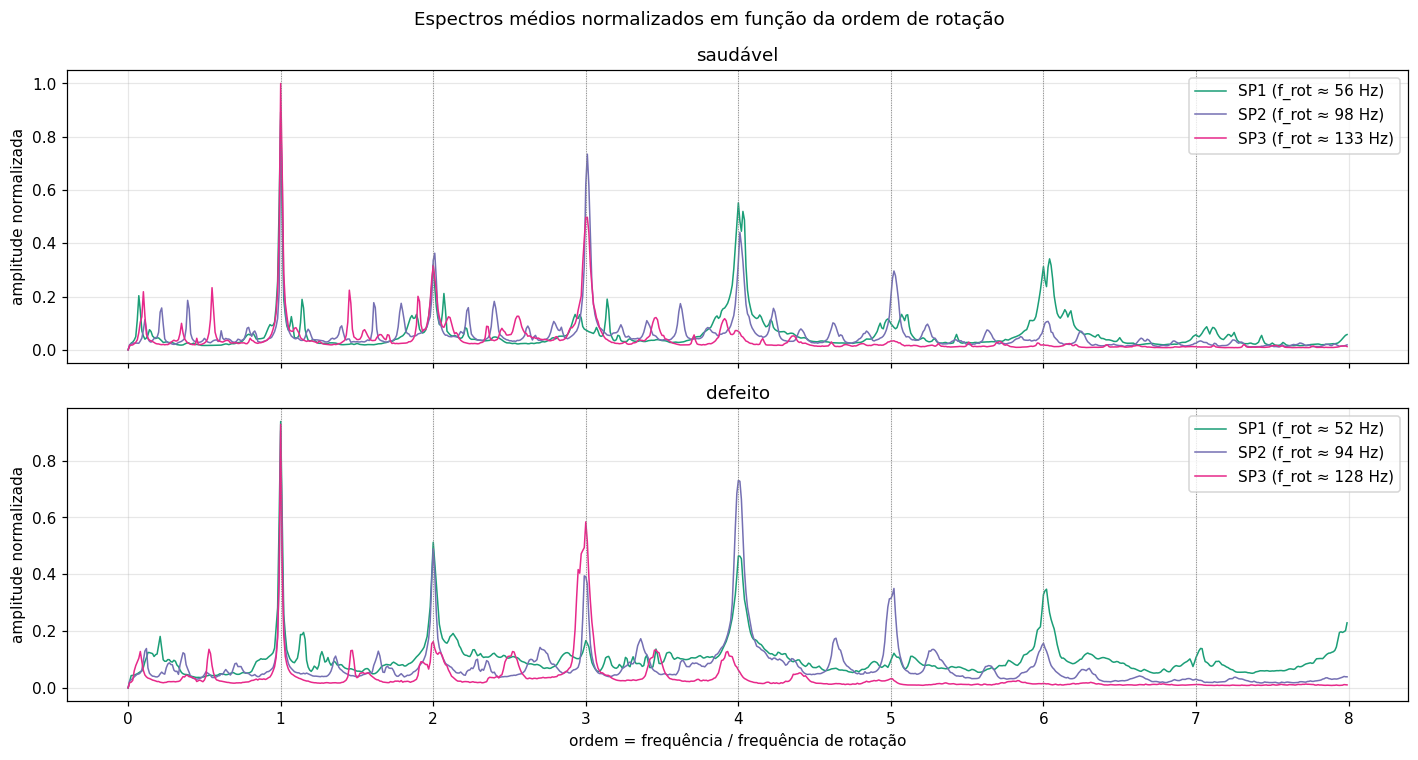

In [32]:
# Espectros em função da ordem (f / f_rot): se os picos são harmônicos da rotação, alinham-se em 1, 2, 3...
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
cores_sp = {'SP1': '#1b9e77', 'SP2': '#7570b3', 'SP3': '#e7298a'}
ordens = np.arange(0, 8, 0.01)
for ax, classe in zip(axes, ['saudável', 'defeito']):
    for sp in VELOCIDADES:
        ids = rot[(rot['velocidade'] == sp) & (rot['classe'] == classe)]
        espectros = []
        for _, r in ids.iterrows():
            f, A = espectro_medio(r['id'])
            espectros.append(np.interp(ordens, f / r['f_rot (Hz)'], A / A.max()))
        ax.plot(ordens, np.mean(espectros, axis=0), color=cores_sp[sp], lw=1,
                label=f"{sp} (f_rot ≈ {ids['f_rot (Hz)'].median():.0f} Hz)")
    ax.set_title(classe); ax.set_ylabel('amplitude normalizada'); ax.legend()
    for k in range(1, 8):
        ax.axvline(k, color='gray', lw=0.6, ls=':')
axes[-1].set_xlabel('ordem = frequência / frequência de rotação')
fig.suptitle('Espectros médios normalizados em função da ordem de rotação')
plt.tight_layout(); plt.show()

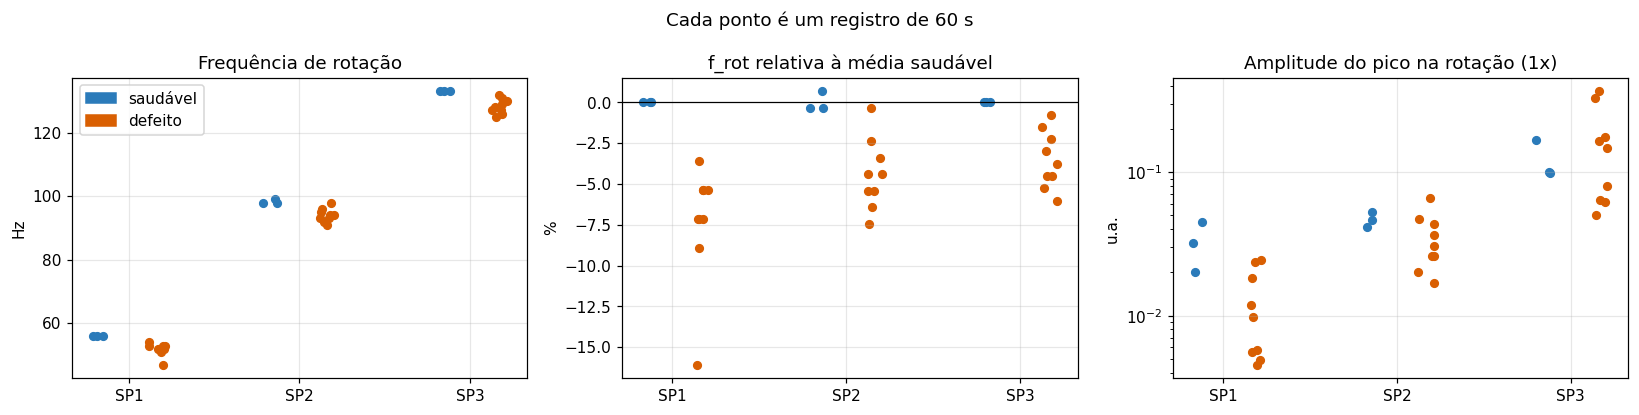

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
paineis = [('f_rot (Hz)', 'Frequência de rotação', 'Hz', False),
           ('desvio de f_rot vs. saudável (%)', 'f_rot relativa à média saudável', '%', False),
           ('amplitude em 1x (u.a.)', 'Amplitude do pico na rotação (1x)', 'u.a.', True)]
rng = np.random.default_rng(0)
for ax, (col, titulo, unidade, log) in zip(axes, paineis):
    for i, sp in enumerate(VELOCIDADES):
        for j, (classe, cor) in enumerate(CORES.items()):
            v = rot.loc[(rot['velocidade'] == sp) & (rot['classe'] == classe), col]
            ax.scatter(3 * i + j + rng.uniform(-0.15, 0.15, len(v)), v, color=cor, s=25)
    ax.set_xticks([0.5, 3.5, 6.5], VELOCIDADES); ax.set_title(titulo); ax.set_ylabel(unidade)
    if log: ax.set_yscale('log')
axes[1].axhline(0, color='k', lw=0.8)
axes[0].legend(handles=[Patch(color=c, label=k) for k, c in CORES.items()])
fig.suptitle('Cada ponto é um registro de 60 s')
plt.tight_layout(); plt.show()

#### Checagem com a configuração C2

Como os saudáveis de C2 são os mesmos de C1 (3.1.3), repetimos a medida da rotação com os 27 registros com defeito de C2, que formam outro experimento. O procedimento é o mesmo das células anteriores.

In [34]:
# Mesma medida de rotação, agora com os registros da configuração C2
def freq_rotacao_sinal(x, sp):
    """Igual a freq_rotacao, mas recebendo o sinal diretamente (C2 não está em `sinais`)."""
    J = janelar(x, N_JAN)
    f = espectro(J[0], FS)[0]
    A = np.mean([espectro(j, FS)[1] for j in J], axis=0)
    m = (f >= FAIXA_ROT[sp][0]) & (f <= FAIXA_ROT[sp][1])
    return f[m][np.argmax(A[m])]

linhas_c2 = []
for _, r in inventario[(inventario['C'] == 2) & (inventario['SP'] > 0)].iterrows():
    x, _, _, _ = carregar_piezo(os.path.join(PASTA, r['id'] + '.mat'))
    sp = f"SP{r['SP']}"
    linhas_c2.append({'id': r['id'], 'classe': 'saudável' if r['F'] == 0 else 'defeito',
                      'velocidade': sp, 'f_rot (Hz)': freq_rotacao_sinal(x, sp)})
rot_c2 = pd.DataFrame(linhas_c2)
ref_c2 = rot_c2[rot_c2['classe'] == 'saudável'].groupby('velocidade')['f_rot (Hz)'].mean()
rot_c2['desvio de f_rot vs. saudável (%)'] = 100 * (rot_c2['f_rot (Hz)'] / rot_c2['velocidade'].map(ref_c2) - 1)

# Em cada configuração e velocidade: mediana do desvio e quantos defeituosos giram abaixo do saudável mais lento
resumo, excecoes = [], []
for nome, tab in [('C1', rot), ('C2', rot_c2)]:
    for sp in VELOCIDADES:
        lento = tab[(tab['velocidade'] == sp) & (tab['classe'] == 'saudável')]['f_rot (Hz)'].min()
        d = tab[(tab['velocidade'] == sp) & (tab['classe'] == 'defeito')]
        resumo.append({'configuração': nome, 'velocidade': sp,
                       'mediana do desvio (%)': round(d['desvio de f_rot vs. saudável (%)'].median(), 2),
                       'defeituosos abaixo do saudável mais lento': f"{(d['f_rot (Hz)'] < lento).sum()} de {len(d)}"})
        excecoes += [f"{nome}: {r['id']} ({r['f_rot (Hz)']:.0f} Hz; saudável mais lento: {lento:.0f} Hz)"
                     for _, r in d[d['f_rot (Hz)'] >= lento].iterrows()]
display(pd.DataFrame(resumo))
print('Registros com defeito que não giram abaixo do saudável mais lento:')
print('\n'.join(excecoes))

,configuração,velocidade,mediana do desvio (%),defeituosos abaixo do saudável mais lento
0,C1,SP1,-7.14,9 de 9
1,C1,SP2,-4.41,8 de 9
2,C1,SP3,-3.76,9 de 9
3,C2,SP1,-7.14,8 de 9
4,C2,SP2,-5.42,7 de 9
5,C2,SP3,-4.51,8 de 9


Registros com defeito que não giram abaixo do saudável mais lento:
C1: F3_SV2_SP2_C1 (98 Hz; saudável mais lento: 98 Hz)
C2: F1_SV1_SP1_C2 (57 Hz; saudável mais lento: 56 Hz)
C2: F1_SV1_SP2_C2 (100 Hz; saudável mais lento: 98 Hz)
C2: F1_SV2_SP2_C2 (98 Hz; saudável mais lento: 98 Hz)
C2: F1_SV1_SP3_C2 (135 Hz; saudável mais lento: 133 Hz)


Resultados:

- **posições:** nas duas classes e nas três velocidades, os picos caem nas ordens inteiras (com a rotação indo de 56 a 133 Hz), como prevê o escalamento;
- **alturas:** não escalam. No saudável a rotação domina em SP3, enquanto o quarto e o sexto harmônicos (SP1) e o terceiro e o quinto (SP2) pesam mais, então a forma da vibração por volta muda com a velocidade;
- **rotação:** em SP1 e SP3 todos os defeitos giram mais devagar que os saudáveis, e em SP2 todos menos um, com desvios medianos de $-7{,}1$ %, $-4{,}4$ % e $-3{,}8$ % (4 a 5 Hz, acima de $\Delta f = 1$ Hz). Os três saudáveis têm a mesma rotação apesar das datas diferentes, então o efeito não parece vir da sessão de ensaio;
- **checagem em C2:** com os mesmos saudáveis, as medianas dos desvios são $-7{,}1$ %, $-5{,}4$ % e $-4{,}5$ %, e 23 de 27 defeituosos giram abaixo do saudável mais lento (26 de 27 em C1). As exceções são todas de F1: SV1 nas três velocidades (cerca de 1,5 % acima do saudável) e SV2 em SP2 (empate). O efeito é nítido para F2 e F3 e não aparece no F1 mais leve;
- **amplitude no primeiro harmônico:** maior no saudável em SP1 (0,032 contra 0,010 u.a.) e em SP2 (0,047 contra 0,031 u.a.), mas inverte em SP3 (0,148 contra 0,101 u.a.).

**Resposta:** a velocidade desloca os picos proporcionalmente, aumenta a intensidade e muda o perfil harmônico. A diferença de intensidade entre as classes não se mantém, mas a rotação mais baixa do defeito aparece nas três velocidades e se repete em C2 (exceto no F1 mais leve), o que a torna uma candidata a característica na classificação. Os dados não permitem dizer por que a hélice danificada gira mais devagar.

## Síntese dos resultados

Os sinais do piezo estão íntegros e são estacionários, o que permitiu um janelamento simples de 1 s. No tempo, as medidas de intensidade são redundantes, dependem sobretudo da velocidade e não indicam mais vibração no defeito; só o fator de crista descreve a forma do sinal. Na frequência, o defeito redistribui a potência entre os harmônicos da rotação e gira um pouco mais devagar, o único efeito presente nas três velocidades, e que se repete em grande parte na configuração C2.

## Tabelas geradas

A célula abaixo salva a tabela de características pedida na especificação, com uma linha por janela de 1 s, as colunas de todas as características, o rótulo da classe e o identificador do registro de origem (`caracteristicas_janelas.csv`, ao lado do notebook). Também salva em `output/tabelas/` as tabelas auxiliares das seções anteriores: registros selecionados, resumos por velocidade e classe, separação $d$, correlações de Spearman e rotação estimada em C1 e C2.

In [35]:
# Tabela de características: uma linha por janela, com o registro de origem, a classe e todas as características
df.to_csv('caracteristicas_janelas.csv', index=False)
print(df.shape, '-> caracteristicas_janelas.csv')

# Tabelas auxiliares usadas no texto e no relatório
auxiliares = {'registros_selecionados': (registros, False),
              'resumo_caracteristicas_tempo': (resumo_tempo, True),
              'resumo_caracteristicas_frequencia': (resumo_freq, True),
              'separacao_d': (sep, True),
              'correlacao_spearman': (corr, True),
              'rotacao_C1': (rot, False),
              'rotacao_C2': (rot_c2, False)}
for nome, (tabela, com_indice) in auxiliares.items():
    tabela.to_csv(os.path.join(PASTA_TABELAS, nome + '.csv'), index=com_indice)
print(len(auxiliares), 'tabelas auxiliares ->', PASTA_TABELAS)

(2160, 22) -> caracteristicas_janelas.csv
7 tabelas auxiliares -> output\tabelas


## Figuras do relatório

Esta célula gera as sete figuras do relatório a partir das mesmas variáveis das seções anteriores, em formato compacto (300 dpi, na largura da página). Os arquivos são salvos em `output/figuras/`, com os mesmos nomes usados no relatório.

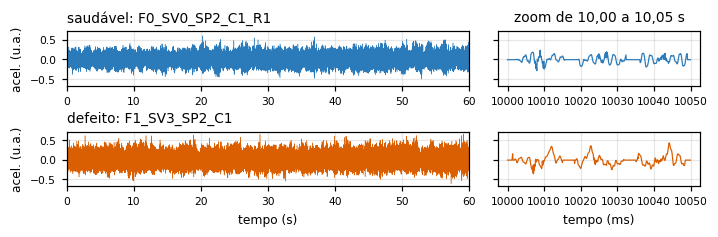

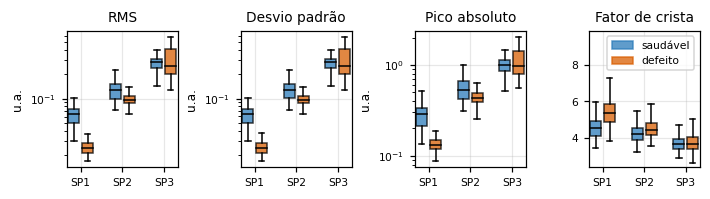

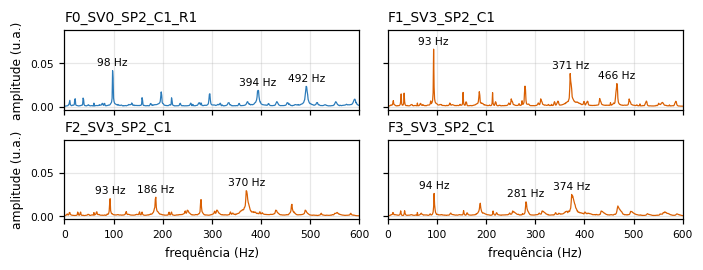

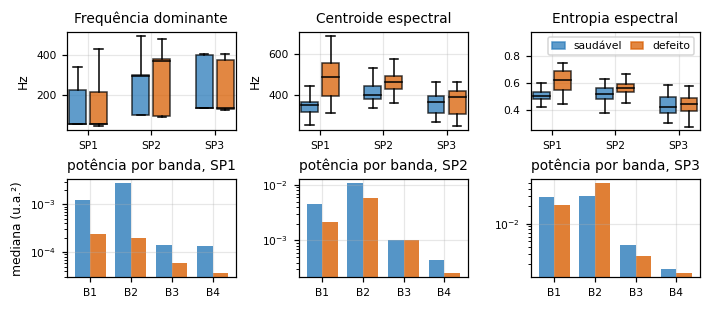

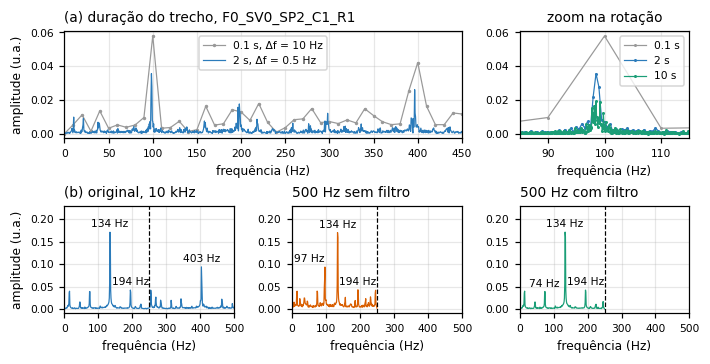

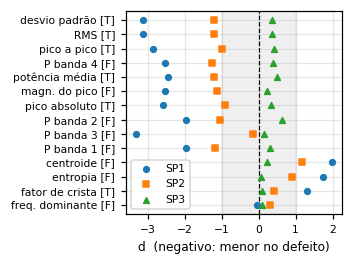

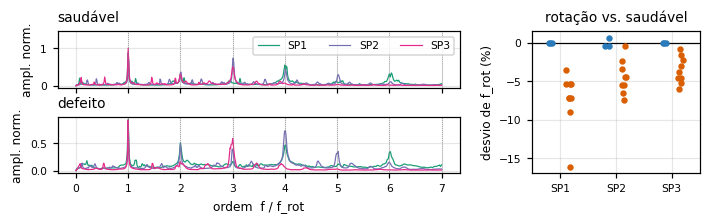

Figuras salvas em output\figuras


In [36]:
# Figuras do relatório: as mesmas análises das seções 3.2 a 3.6, em formato compacto, salvas em PNG (300 dpi).
from matplotlib.ticker import NullFormatter

PASTA_FIG = PASTA_FIGURAS

ESTILO_RELATORIO = {'font.size': 8, 'axes.titlesize': 9, 'axes.labelsize': 8, 'xtick.labelsize': 7,
                    'ytick.labelsize': 7, 'legend.fontsize': 7, 'figure.dpi': 110}
LEGENDA_CLASSES = [Patch(color=c, label=k, alpha=0.75) for k, c in CORES.items()]

def salvar(fig, nome):
    fig.savefig(os.path.join(PASTA_FIG, nome), dpi=300, bbox_inches='tight')
    plt.show()

def espaco_no_topo(ax, fracao):
    """Aumenta o limite superior do eixo y em `fracao` da faixa, para a legenda não cobrir os dados."""
    y0, y1 = ax.get_ylim()
    ax.set_ylim(y0, y1 + fracao * (y1 - y0))

def anotar_picos(ax, f, A, xmax, n=3, fmin=20, distancia=15, linhas=()):
    """Anota os n maiores picos até xmax (chamar depois de fixar os limites e o layout).
    Para cada pico, testa o rótulo centrado, à esquerda e à direita, e fica com a primeira posição
    que não sai do painel, não cruza as linhas verticais em `linhas`, não encosta em outro rótulo
    e não fica sobre um trecho mais alto do espectro."""
    rend = ax.figure.canvas.get_renderer()
    para_dados = ax.transData.inverted()
    xa, xb = ax.get_xlim()
    ytopo = ax.get_ylim()[1]
    m = f <= xmax
    f, A = f[m], A[m]
    caixas, escolhidos = [], []
    for i in np.argsort(A)[::-1]:
        if f[i] < fmin or any(abs(f[i] - f[j]) < distancia for j in escolhidos):
            continue
        escolhidos.append(i)
        for ha in ['center', 'right', 'left', 'center']:
            t = ax.annotate(f'{f[i]:.0f} Hz', (f[i], A[i]), textcoords='offset points', xytext=(0, 2),
                            ha=ha, va='bottom', fontsize=7)
            (x0, y0), (x1, y1) = para_dados.transform(t.get_window_extent(rend).get_points())
            trecho = A[(f >= x0) & (f <= x1)]
            livre = (x0 >= xa and x1 <= xb and y1 <= ytopo
                     and not any(x0 < l < x1 for l in linhas)
                     and not (trecho.size and trecho.max() > y0)
                     and not any(x0 < c[2] and c[0] < x1 and y0 < c[3] and c[1] < y1 for c in caixas))
            if livre:
                break
            t.remove()
        else:   # nenhuma posição livre: fica a centrada
            t = ax.annotate(f'{f[i]:.0f} Hz', (f[i], A[i]), textcoords='offset points', xytext=(0, 2),
                            ha='center', va='bottom', fontsize=7)
        caixas.append((x0, y0, x1, y1))
        if len(escolhidos) == n:
            break

with plt.rc_context(ESTILO_RELATORIO):
    # Figura 1: sinal no tempo (seção 3.2)
    fig, axes = plt.subplots(2, 2, figsize=(6.5, 2.2), sharey=True, gridspec_kw={'width_ratios': [2, 1]})
    for linha, (rid, classe) in enumerate([(SAUDAVEL_EX, 'saudável'), (DEFEITO_EX, 'defeito')]):
        x = sinais[rid]
        t = np.arange(len(x)) / FS
        axes[linha, 0].plot(t, x, color=CORES[classe], lw=0.3)
        axes[linha, 0].set_xlim(0, 60)
        axes[linha, 0].set_title(f'{classe}: {rid}', loc='left')
        axes[linha, 0].set_ylabel('acel. (u.a.)')
        trecho = (t >= 10) & (t < 10.05)
        axes[linha, 1].plot(t[trecho] * 1000, x[trecho], color=CORES[classe], lw=0.8)
    axes[0, 1].set_title('zoom de 10,00 a 10,05 s')
    axes[1, 0].set_xlabel('tempo (s)'); axes[1, 1].set_xlabel('tempo (ms)')
    fig.tight_layout(h_pad=0.4)
    salvar(fig, 'fig_tempo.png')

    # Figura 2: características temporais (seção 3.2)
    fig, axes = plt.subplots(1, 4, figsize=(6.5, 1.85))
    for ax, (col, titulo, log) in zip(axes, [('RMS', 'RMS', True), ('desvio padrão', 'Desvio padrão', True),
                                             ('pico absoluto', 'Pico absoluto', True), ('fator de crista', 'Fator de crista', False)]):
        boxplot_por_velocidade(ax, df, col, titulo, 'u.a.' if log else '', log=log)
        ax.yaxis.set_minor_formatter(NullFormatter())
    espaco_no_topo(axes[3], 0.45)
    axes[3].legend(handles=LEGENDA_CLASSES, loc='upper right')
    fig.tight_layout(w_pad=0.6)
    salvar(fig, 'fig_box_tempo.png')

    # Figura 3: espectros médios em SP2 (seção 3.3)
    fig, axes = plt.subplots(2, 2, figsize=(6.5, 2.5), sharex=True, sharey=True)
    espectros_sp2 = []
    for ax, (rid, classe) in zip(axes.ravel(), comparacoes):
        f, A = espectro_medio(rid)
        espectros_sp2.append((f, A))
        ax.plot(f, A, color=CORES[classe], lw=0.8)
        ax.set_xlim(0, 600)
        ax.set_title(rid, loc='left')
    espaco_no_topo(axes[0, 0], 0.25)
    for ax in axes[:, 0]:
        ax.set_ylabel('amplitude (u.a.)')
    for ax in axes[1]:
        ax.set_xlabel('frequência (Hz)')
    fig.tight_layout(h_pad=0.4)
    for ax, (f, A) in zip(axes.ravel(), espectros_sp2):
        anotar_picos(ax, f, A, 600)
    salvar(fig, 'fig_espectros.png')

    # Figura 4: características espectrais e potência por banda (seção 3.3)
    fig, axes = plt.subplots(2, 3, figsize=(6.5, 2.85))
    for ax, (col, titulo, unidade) in zip(axes[0], [('freq. dominante (Hz)', 'Frequência dominante', 'Hz'),
                                                     ('centroide espectral (Hz)', 'Centroide espectral', 'Hz'),
                                                     ('entropia espectral', 'Entropia espectral', '')]):
        boxplot_por_velocidade(ax, df, col, titulo, unidade)
    espaco_no_topo(axes[0, 2], 0.4)
    axes[0, 2].legend(handles=LEGENDA_CLASSES, loc='upper right', ncol=2, columnspacing=0.8, handlelength=1.2)
    largura = 0.38
    for ax, sp in zip(axes[1], VELOCIDADES):
        for j, (classe, cor) in enumerate(CORES.items()):
            med = df.loc[(df['SP'] == sp) & (df['classe'] == classe), nomes_bandas].median()
            ax.bar(np.arange(len(nomes_bandas)) + (j - 0.5) * largura, med, largura, color=cor, alpha=0.8)
        ax.set_xticks(range(len(nomes_bandas)), ['B1', 'B2', 'B3', 'B4'])
        ax.set_yscale('log'); ax.set_title(f'potência por banda, {sp}')
        ax.yaxis.set_minor_formatter(NullFormatter())
    axes[1, 0].set_ylabel('mediana (u.a.²)')
    fig.tight_layout(h_pad=0.6)
    salvar(fig, 'fig_freq_caract.png')

    # Figura 5: (a) resolução espectral e (b) aliasing (seções 3.3.6 e 3.3.7)
    fig = plt.figure(figsize=(6.5, 3.35))
    gs = fig.add_gridspec(2, 3)
    ax_a, ax_zoom = fig.add_subplot(gs[0, :2]), fig.add_subplot(gs[0, 2])
    x = sinais[SAUDAVEL_EX]
    for dur, cor in [(0.1, '#999999'), (2.0, '#2b7bba'), (10.0, '#1b9e77')]:
        N = int(dur * FS)
        f, A, _ = espectro(x[:N], FS)
        if dur < 10:
            ax_a.plot(f, A, '.-' if dur < 1 else '-', color=cor, lw=0.8, ms=2.5, label=f'{dur:g} s, Δf = {FS / N:g} Hz')
        ax_zoom.plot(f, A, '.-', color=cor, lw=0.8, ms=2, label=f'{dur:g} s')
    ax_a.set_xlim(0, 450); ax_zoom.set_xlim(85, 115)
    ax_a.set_title(f'(a) duração do trecho, {SAUDAVEL_EX}', loc='left'); ax_zoom.set_title('zoom na rotação')
    ax_a.legend(loc='upper center'); ax_zoom.legend(loc='upper right')
    ax_a.set_ylabel('amplitude (u.a.)')
    for ax in (ax_a, ax_zoom):
        ax.set_xlabel('frequência (Hz)')
    eixos_b = [fig.add_subplot(gs[1, k]) for k in range(3)]
    titulos_b = ['(b) original, 10 kHz', '500 Hz sem filtro', '500 Hz com filtro']
    cores_b = ['#2b7bba', '#d95f02', '#1b9e77']
    espectros_b = []
    for ax, (sinal, fs, _, _), titulo, cor in zip(eixos_b, casos, titulos_b, cores_b):
        f, A = espectro_longo(sinal, fs, int(fs))
        espectros_b.append((f, A))
        ax.plot(f, A, color=cor, lw=0.8)
        ax.axvline(FS_NOVA / 2, color='k', ls='--', lw=0.8)
        ax.set_xlim(0, 500); ax.set_ylim(top=0.23)
        ax.set_title(titulo, loc='left'); ax.set_xlabel('frequência (Hz)')
    eixos_b[0].set_ylabel('amplitude (u.a.)')
    fig.tight_layout(h_pad=0.6)
    for ax, (f, A) in zip(eixos_b, espectros_b):
        anotar_picos(ax, f, A, 500, linhas=[FS_NOVA / 2])
    salvar(fig, 'fig_res_alias.png')

    # Figura 6: separação entre as classes (seção 3.4)
    curtos = {'freq. dominante (Hz)': 'freq. dominante', 'magnitude do pico': 'magn. do pico',
              'centroide espectral (Hz)': 'centroide', 'entropia espectral': 'entropia'}
    curtos.update({b: f'P banda {k + 1}' for k, b in enumerate(BANDAS)})
    fig, ax = plt.subplots(figsize=(3.25, 2.45))
    for i, sp in enumerate(VELOCIDADES):
        ax.scatter(sep.loc[ordem, sp], range(len(ordem)), label=sp, s=14, marker='os^'[i], zorder=3)
    ax.axvline(0, color='k', lw=0.8, ls='--')
    ax.axvspan(-1, 1, color='gray', alpha=0.12)
    ax.set_yticks(range(len(ordem)), [f"{curtos.get(c, c)} [{sep.loc[c, 'domínio'][0].upper()}]" for c in ordem])
    ax.set_xlabel('d  (negativo: menor no defeito)')
    ax.legend(loc='lower left')
    fig.tight_layout()
    salvar(fig, 'fig_separacao.png')

    # Figura 7: espectros por ordem de rotação e desvio da rotação (seção 3.6)
    fig = plt.figure(figsize=(6.5, 2.08))
    gs = fig.add_gridspec(2, 2, width_ratios=[2.4, 1])
    eixos_ord = [fig.add_subplot(gs[0, 0])]
    eixos_ord.append(fig.add_subplot(gs[1, 0], sharex=eixos_ord[0]))
    ate7 = ordens <= 7
    for ax, classe in zip(eixos_ord, ['saudável', 'defeito']):
        for sp in VELOCIDADES:
            ids = rot[(rot['velocidade'] == sp) & (rot['classe'] == classe)]
            espectros = []
            for _, r in ids.iterrows():
                f, A = espectro_medio(r['id'])
                espectros.append(np.interp(ordens[ate7], f / r['f_rot (Hz)'], A / A.max()))
            ax.plot(ordens[ate7], np.mean(espectros, axis=0), color=cores_sp[sp], lw=0.8, label=sp)
        for k in range(1, 8):
            ax.axvline(k, color='gray', lw=0.5, ls=':')
        ax.set_title(classe, loc='left'); ax.set_ylabel('ampl. norm.')
    eixos_ord[0].set_ylim(top=1.45)
    eixos_ord[0].legend(loc='upper right', ncol=3)
    eixos_ord[0].tick_params(labelbottom=False)
    eixos_ord[1].set_xlabel('ordem  f / f_rot')
    ax = fig.add_subplot(gs[:, 1])
    rng = np.random.default_rng(0)        # espalhamento horizontal só para os pontos não se sobreporem
    for i, sp in enumerate(VELOCIDADES):
        for desloc, classe in [(-0.15, 'saudável'), (0.15, 'defeito')]:
            v = rot.loc[(rot['velocidade'] == sp) & (rot['classe'] == classe), 'desvio de f_rot vs. saudável (%)']
            ax.scatter(i + desloc + rng.uniform(-0.05, 0.05, len(v)), v, s=10, color=CORES[classe], zorder=3)
    ax.axhline(0, color='k', lw=0.8)
    ax.set_xticks(range(3), VELOCIDADES); ax.set_xlim(-0.5, 2.5)
    ax.set_ylabel('desvio de f_rot (%)'); ax.set_title('rotação vs. saudável')
    fig.tight_layout(h_pad=0.3, w_pad=0.8)
    salvar(fig, 'fig_investigacao.png')

print('Figuras salvas em', PASTA_FIG)